# Reproduce Table 5: MangoMamba 3-Phase Curriculum Training

Clones the training pipeline from the paper's Table 5 using **3-phase curriculum learning**:

| Phase | Dataset | Classes | Purpose |
|-------|---------|---------|--------|
| 1 | MangoLeafBD | 8 | Source domain feature initialization |
| 2 | Combined Dataset (40K) | 8 | Robustness to environmental variations |
| 3 | VN-MangoLeaf | 7 | Target domain adaptation (Vietnam) |

**Hyperparameters (Table 5):** Batch=256, LR=5e-4, Warmup=5, Patience=20, AdamW+Cosine

**Hardware:** ASUS Ascent GX10 (NVIDIA GB10, aarch64, CUDA 13.0)

---
**Setup:** Build the Docker image first, then connect this notebook to it as kernel:

```bash
# 1. Build
cd /path/to/Mango-Mamba
docker build -t mangomamba-repro -f reproduce/Dockerfile .

# 2. Start Jupyter inside container
docker run --rm -d --gpus all --shm-size=8g --name mangomamba-jupyter \
    -v $(pwd):/app -w /app -p 8888:8888 mangomamba-repro \
    jupyter notebook --ip=0.0.0.0 --port=8888 --allow-root --no-browser \
    --NotebookApp.token=mangomamba --NotebookApp.password= /app/reproduce/

# 3. Open http://localhost:8888, open reproduce_table5.ipynb, run top to bottom
```

## 0. Verify Docker Environment

In [1]:
import sys, platform, os, shutil

print(f'Python: {sys.version}')
print(f'Platform: {platform.platform()}')
print(f'Architecture: {platform.machine()}')

if os.path.exists('/.dockerenv'):
    print('[OK] Running inside Docker container')
else:
    print('[WARN] Not inside Docker')

import torch
print(f'PyTorch: {torch.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'CUDA version: {torch.version.cuda}')
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    free_b, total_b = torch.cuda.mem_get_info(0)
    print(f'GPU memory: {total_b/1024**3:.1f} GB total, {free_b/1024**3:.1f} GB free')

import mamba_ssm
print(f'mamba_ssm: {mamba_ssm.__version__}')

if torch.cuda.is_available():
    try:
        from mamba_ssm.ops.selective_scan_interface import selective_scan_fn
        B, d, l = 2, 36, 64
        x = torch.randn(B, d, l, device='cuda')
        dt = torch.randn(B, d, l, device='cuda')
        A = torch.randn(d, 8, device='cuda')
        Bm = torch.randn(B, 8, l, device='cuda')
        Cm = torch.randn(B, 8, l, device='cuda')
        D = torch.ones(d, device='cuda')
        selective_scan_fn(x, dt, A, Bm, Cm, D, z=None, delta_bias=None, delta_softplus=True)
        print('[OK] mamba selective_scan CUDA kernel runs on this GPU')
    except Exception as e:
        print(f'[ERROR] mamba CUDA kernel test failed: {e}')

shm_total_gb = shutil.disk_usage('/dev/shm').total / (1024**3)
print(f'/dev/shm size: {shm_total_gb:.2f} GB')
if shm_total_gb < 2.0:
    print('[WARN] /dev/shm is small -- restart container with --shm-size=8g')
else:
    print('[OK] /dev/shm is large enough for DataLoader workers')

print(f'Working directory: {os.getcwd()}')

Python: 3.12.3 (main, Mar 23 2026, 19:04:32) [GCC 13.3.0]
Platform: Linux-6.17.0-1008-nvidia-aarch64-with-glibc2.39
Architecture: aarch64
[OK] Running inside Docker container
PyTorch: 2.12.0.dev20260407+cu128
CUDA available: True
CUDA version: 12.8
GPU: NVIDIA GB10
GPU memory: 119.6 GB total, 80.8 GB free
mamba_ssm: 2.3.0
[OK] mamba selective_scan CUDA kernel runs on this GPU
/dev/shm size: 8.00 GB
[OK] /dev/shm is large enough for DataLoader workers
Working directory: /app/reproduce


## 1. Extract Datasets from Zip Files

In [2]:
import os, shutil, zipfile, glob


def get_project_root():
    cwd = os.path.abspath(os.getcwd())
    if os.path.basename(cwd) == 'reproduce':
        return os.path.dirname(cwd)
    return cwd


def ensure_project_root():
    root = get_project_root()
    os.chdir(root)
    return root


def extract_dataset(target, zip_pattern):
    """Extract dataset zip into target/ unless train/ already exists."""
    train_path = os.path.join(target, 'train')
    if os.path.isdir(train_path) and os.listdir(train_path):
        classes = sorted(os.listdir(train_path))
        print(f'{target}: already present ({len(classes)} train classes)')
        return True

    os.makedirs(target, exist_ok=True)
    zip_files = sorted(glob.glob(zip_pattern))
    if not zip_files:
        print(f'ERROR: {zip_pattern} not found in {os.getcwd()}')
        return False

    print(f'Extracting {zip_files[0]} -> {target}/ ...')
    with zipfile.ZipFile(zip_files[0], 'r') as zf:
        zf.extractall(target)

    subdirs = [
        d for d in os.listdir(target)
        if os.path.isdir(os.path.join(target, d)) and d not in ('train', 'val', 'test')
    ]
    for d in subdirs:
        src = os.path.join(target, d)
        for item in os.listdir(src):
            s, t = os.path.join(src, item), os.path.join(target, item)
            if not os.path.exists(t):
                shutil.move(s, t)
        shutil.rmtree(src)

    if not os.path.isdir(train_path):
        print(f'ERROR: no train/ split after extracting {target}')
        return False

    classes = sorted(os.listdir(train_path))
    print(f'{target}: {len(classes)} classes -> {classes}')
    return True


def dev_shm_size_gb():
    import shutil
    return shutil.disk_usage('/dev/shm').total / (1024**3)


def dataloader_workers(batch_size=256, min_shm_gb=2.0, preferred=2):
    shm_gb = dev_shm_size_gb()
    if shm_gb < min_shm_gb:
        print(f'[WARN] /dev/shm={shm_gb:.2f} GB -- using --workers=0')
        return 0
    workers = min(preferred, 2) if (batch_size >= 256 and shm_gb < 4.0) else preferred
    print(f'[OK] /dev/shm={shm_gb:.2f} GB -- using --workers={workers}')
    return workers


PROJECT_ROOT = ensure_project_root()
print(f'Working directory: {PROJECT_ROOT}')

Working directory: /app


In [3]:
ensure_project_root()
extract_dataset('datasets/mangoleafBD', 'mangoleafBD-*.zip')

mangoleafBD: already present (8 train classes)


True

In [4]:
ensure_project_root()
extract_dataset('datasets/combined_dataset', 'combined_dataset-*.zip')

combined_dataset: already present (8 train classes)


True

In [5]:
ensure_project_root()
extract_dataset('datasets/vn_mangoleaf', 'vn_mangoleaf-*.zip')

vn_mangoleaf: already present (7 train classes)


True

## 2. Visualization Helper Utilities

Shared helpers for loading saved results and displaying them inline after each training phase.

In [6]:
import json, glob, os
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from PIL import Image

matplotlib.rcParams['figure.dpi'] = 100


def find_latest_run(output_dir_pattern):
    """Return the most recent training run directory matching a glob pattern."""
    runs = sorted(glob.glob(output_dir_pattern))
    if not runs:
        print(f'[WARN] No run directory found for: {output_dir_pattern}')
        return None
    return runs[-1]


def load_training_results(run_dir):
    path = os.path.join(run_dir, 'training_results.json')
    if not os.path.exists(path):
        print(f'[WARN] training_results.json not found in {run_dir}')
        return None
    with open(path) as f:
        return json.load(f)


def display_metrics_table(results, phase_label):
    """Display a formatted HTML metrics table."""
    if results is None:
        return
    vm = results.get('validation_metrics', {})
    tm = results.get('test_metrics', {})
    es = results.get('early_stopping', {})
    html = f"""
    <h3 style='font-family:sans-serif;color:#2c3e50;'>{phase_label} — Performance Metrics</h3>
    <table style='border-collapse:collapse;font-family:sans-serif;font-size:14px;width:620px;'>
      <thead>
        <tr style='background:#2c3e50;color:white;'>
          <th style='padding:8px 12px;text-align:left;'>Metric</th>
          <th style='padding:8px 12px;text-align:center;'>Validation</th>
          <th style='padding:8px 12px;text-align:center;'>Test</th>
        </tr>
      </thead>
      <tbody>
        <tr style='background:#ecf0f1;'><td style='padding:6px 12px;font-weight:bold;'>Accuracy</td>
          <td style='padding:6px 12px;text-align:center;'>{vm.get('accuracy',0)*100:.2f}%</td>
          <td style='padding:6px 12px;text-align:center;'>{tm.get('accuracy',0)*100:.2f}%</td></tr>
        <tr><td style='padding:6px 12px;font-weight:bold;'>Precision (weighted)</td>
          <td style='padding:6px 12px;text-align:center;'>{vm.get('precision',0)*100:.2f}%</td>
          <td style='padding:6px 12px;text-align:center;'>{tm.get('precision',0)*100:.2f}%</td></tr>
        <tr style='background:#ecf0f1;'><td style='padding:6px 12px;font-weight:bold;'>Recall (weighted)</td>
          <td style='padding:6px 12px;text-align:center;'>{vm.get('recall',0)*100:.2f}%</td>
          <td style='padding:6px 12px;text-align:center;'>{tm.get('recall',0)*100:.2f}%</td></tr>
        <tr><td style='padding:6px 12px;font-weight:bold;'>F1-Score (weighted)</td>
          <td style='padding:6px 12px;text-align:center;'>{vm.get('f1_score',0)*100:.2f}%</td>
          <td style='padding:6px 12px;text-align:center;'>{tm.get('f1_score',0)*100:.2f}%</td></tr>
        <tr style='background:#ecf0f1;'><td style='padding:6px 12px;font-weight:bold;'>Best Val Acc (epoch {results.get('best_epoch','?')})</td>
          <td style='padding:6px 12px;text-align:center;'>{results.get('best_validation_accuracy',0):.4f}%</td>
          <td style='padding:6px 12px;text-align:center;'>—</td></tr>
        <tr><td style='padding:6px 12px;font-weight:bold;'>Epochs Completed</td>
          <td style='padding:6px 12px;text-align:center;' colspan='2'>{es.get('epochs_completed',results.get('epochs_completed','?'))}</td></tr>
        <tr style='background:#ecf0f1;'><td style='padding:6px 12px;font-weight:bold;'>Training Time</td>
          <td style='padding:6px 12px;text-align:center;' colspan='2'>{results.get('training_time_formatted','?')}</td></tr>
      </tbody>
    </table>
    """
    display(HTML(html))


def display_per_class_metrics(results, split='validation'):
    if results is None:
        return
    pcm = results.get(f'{split}_per_class_metrics', {})
    if not pcm:
        return
    class_names = pcm.get('class_names', [])
    precision = pcm.get('precision', [])
    recall = pcm.get('recall', [])
    f1 = pcm.get('f1_score', [])
    n = len(class_names)
    x = np.arange(n)
    width = 0.25
    fig, ax = plt.subplots(figsize=(max(10, n*1.3), 5))
    ax.bar(x - width, [p*100 for p in precision], width, label='Precision', color='#3498db', alpha=0.85)
    ax.bar(x,         [r*100 for r in recall],    width, label='Recall',    color='#2ecc71', alpha=0.85)
    ax.bar(x + width, [f*100 for f in f1],        width, label='F1-Score',  color='#e74c3c', alpha=0.85)
    ax.set_xlabel('Class', fontsize=12)
    ax.set_ylabel('Score (%)', fontsize=12)
    ax.set_title(f'Per-Class Metrics — {split.capitalize()} Set', fontsize=14, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(class_names, rotation=30, ha='right', fontsize=10)
    ax.set_ylim(0, 105)
    ax.legend(fontsize=11)
    ax.grid(axis='y', alpha=0.3)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0f}%'))
    plt.tight_layout()
    plt.show()


def display_image_file(path, title=None, figsize=(14, 5)):
    if not os.path.exists(path):
        print(f'[WARN] Image not found: {path}')
        return
    img = Image.open(path)
    fig, ax = plt.subplots(figsize=figsize)
    ax.imshow(img)
    ax.axis('off')
    if title:
        ax.set_title(title, fontsize=13, fontweight='bold', pad=10)
    plt.tight_layout()
    plt.show()


def display_gradcam_grid(run_dir, class_names, title_prefix=''):
    cam_files = []
    for cls in class_names:
        safe = cls.replace(' ', '_')
        path = os.path.join(run_dir, f'gradcam_{safe}.png')
        if os.path.exists(path):
            cam_files.append((cls, path))
        else:
            matches = glob.glob(os.path.join(run_dir, f'gradcam_{safe}*.png'))
            if matches:
                cam_files.append((cls, matches[0]))
            else:
                print(f'  [WARN] GradCAM not found for: {cls}')
    if not cam_files:
        print('[WARN] No GradCAM files found.')
        return
    n = len(cam_files)
    cols = min(4, n)
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols*5, rows*4))
    axes_flat = np.array(axes).reshape(-1) if n > 1 else [axes]
    for ax, (cls_name, path) in zip(axes_flat, cam_files):
        ax.imshow(Image.open(path))
        ax.set_title(cls_name, fontsize=11, fontweight='bold')
        ax.axis('off')
    for ax in axes_flat[len(cam_files):]:
        ax.axis('off')
    fig.suptitle(f'{title_prefix} Grad-CAM Visualizations', fontsize=14, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.show()


def display_phase_results(output_dir_pattern, phase_label, class_names):
    """Full display pipeline: metrics, curves, per-class charts, confusion matrices, GradCAMs."""
    run_dir = find_latest_run(output_dir_pattern)
    if run_dir is None:
        print(f'[ERROR] No run directory for {output_dir_pattern}')
        return None
    print(f'Loading from: {run_dir}')
    results = load_training_results(run_dir)

    display(HTML(f'<h2 style="font-family:sans-serif;color:#1a252f;border-bottom:2px solid #3498db;padding-bottom:4px">{phase_label} — Results</h2>'))
    display_metrics_table(results, phase_label)

    display(HTML('<h3 style="font-family:sans-serif;color:#2c3e50;">Training Curves</h3>'))
    display_image_file(os.path.join(run_dir, 'training_curves.png'), figsize=(16, 5))

    display(HTML('<h3 style="font-family:sans-serif;color:#2c3e50;">Per-Class Metrics — Validation Set</h3>'))
    display_per_class_metrics(results, split='validation')

    display(HTML('<h3 style="font-family:sans-serif;color:#2c3e50;">Per-Class Metrics — Test Set</h3>'))
    display_per_class_metrics(results, split='test')

    display(HTML('<h3 style="font-family:sans-serif;color:#2c3e50;">Confusion Matrices</h3>'))
    cm_val  = os.path.join(run_dir, 'confusion_matrix_val.png')
    cm_test = os.path.join(run_dir, 'confusion_matrix_test.png')
    fig, axes = plt.subplots(1, 2, figsize=(20, 8))
    for ax, path, lbl in zip(axes, [cm_val, cm_test], ['Validation Set', 'Test Set']):
        if os.path.exists(path):
            ax.imshow(Image.open(path))
        ax.set_title(lbl, fontsize=13, fontweight='bold')
        ax.axis('off')
    fig.suptitle(f'{phase_label} Confusion Matrices', fontsize=15, fontweight='bold')
    plt.tight_layout()
    plt.show()

    display(HTML('<h3 style="font-family:sans-serif;color:#2c3e50;">Grad-CAM Visualizations</h3>'))
    display_gradcam_grid(run_dir, class_names, title_prefix=phase_label)

    return run_dir, results


print('[OK] Visualization helpers loaded.')

[OK] Visualization helpers loaded.


---
## Phase 1: Train on MangoLeafBD (8 classes)

**Purpose:** Establish foundational mango lesion feature representations.

**Hyperparameters:** Batch=256, LR=5e-4, Warmup=5, Patience=20, Epochs=100

In [7]:
import os, subprocess

root = ensure_project_root()
workers = dataloader_workers(batch_size=256)

subprocess.run([
    'python3', 'train_mango_mamba.py',
    '--epochs=100',
    '--batch-size=256',
    f'--workers={workers}',
    '--data_dir=datasets/mangoleafBD',
    '--lr=5e-4',
    '--min-lr=5e-6',
    '--warmup-epochs=5',
    '--patience-epochs=20',
    '--num-classes=8',
    '--output=./output_phase1',
    '--experiment=mangoleafbd_phase1',
    '--smoothing=0.01',
    '--drop-path-rate=0.01',
    '--seed=42',
    '--amp',
], check=True, cwd=root)
print('Phase 1 training complete.')

[OK] /dev/shm=8.00 GB -- using --workers=2


/opt/venv/lib/python3.12/site-packages/timm/utils/cuda.py:50: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  self._scaler = torch.cuda.amp.GradScaler()
Using native Torch AMP for mixed precision training.
Data processing configuration for current model + dataset:
	input_size: (3, 224, 224)
	interpolation: bicubic
	mean: (0.485, 0.456, 0.406)
	std: (0.229, 0.224, 0.225)
	crop_pct: 0.875
	crop_mode: center
Starting training for 100 epochs...



Model Parameters:
  Total parameters: 5,810,428
  Trainable parameters: 5,810,428
  Model size: 22.17 MB (float32)



Train: 0 [   0/12 (  0%)] Loss: 2.119 (2.12) Acc@1: 3.91 (3.91) Time: 20.966s LR: 1.000e-05 Data: 0.627s
Test: [   0/3] Time: 0.816 (0.816) Loss:  2.0716 (2.0716) Acc@1: 39.0625 (39.0625)
Current checkpoints:
 ('./output_phase1/mangoleafbd_phase1-20260705-123530/checkpoint-0.pth.tar', 12.5)

Epoch 1/100 - Train Loss: 2.0958 - Val Acc: 12.5000 - Best Acc: 12.5000 (epoch 1) - Val Loss: 2.0794 (best: 2.0794) - Patience: 0/20
Train: 1 [   0/12 (  0%)] Loss: 2.072 (2.07) Acc@1: 10.2 (10.2) Time: 2.874s LR: 1.080e-04 Data: 0.348s
Test: [   0/3] Time: 0.568 (0.568) Loss:  2.0250 (2.0250) Acc@1: 42.1875 (42.1875)
Current checkpoints:
 ('./output_phase1/mangoleafbd_phase1-20260705-123530/checkpoint-1.pth.tar', 13.625)
 ('./output_phase1/mangoleafbd_phase1-20260705-123530/checkpoint-0.pth.tar', 12.5)

Epoch 2/100 - Train Loss: 1.9102 - Val Acc: 13.6250 - Best Acc: 13.6250 (epoch 2) - Val Loss: 2.0641 (best: 2.0641) - Patience: 0/20
Train: 2 [   0/12 (  0%)] Loss: 1.734 (1.73) Acc@1: 51.6 (51.6) 

Lightweight checkpoint saved to: ./output_phase1/mangoleafbd_phase1-20260705-123530/model_best_inference.pth
Lightweight checkpoint saved to: ./output_phase1/mangoleafbd_phase1-20260705-123530/model_best_inference.pth
Lightweight checkpoint saved to: ./output_phase1/mangoleafbd_phase1-20260705-123530/model_best_inference.pth
Lightweight checkpoint saved to: ./output_phase1/mangoleafbd_phase1-20260705-123530/model_best_inference.pth
Lightweight checkpoint saved to: ./output_phase1/mangoleafbd_phase1-20260705-123530/model_best_inference.pth
Lightweight checkpoint saved to: ./output_phase1/mangoleafbd_phase1-20260705-123530/model_best_inference.pth
Lightweight checkpoint saved to: ./output_phase1/mangoleafbd_phase1-20260705-123530/model_best_inference.pth
Lightweight checkpoint saved to: ./output_phase1/mangoleafbd_phase1-20260705-123530/model_best_inference.pth
Lightweight checkpoint saved to: ./output_phase1/mangoleafbd_phase1-20260705-123530/model_best_inference.pth
Lightweight checkpo

Test: [   0/1] Time: 0.726 (0.726) Loss:  0.0403 (0.0403) Acc@1: 99.2188 (99.2188)
Training completed! Best validation accuracy: 99.2500 (epoch 98)
Total training time: 0h 46m 51s
Model parameters: 5,810,428 trainable / 5,810,428 total
Early stopping: Not triggered (patience: 20 epochs, monitor: loss)
Best model metrics - Train Acc: 99.77% | Val Acc: 99.25% | Test Acc: 99.25%
Best model metrics - Train Loss: 0.0826 | Val Loss: 0.0324 | Test Loss: 0.0340
Validation metrics - Accuracy: 0.9950 | Precision: 0.9951 | Recall: 0.9950 | F1: 0.9950
Test metrics - Accuracy: 0.9925 | Precision: 0.9927 | Recall: 0.9925 | F1: 0.9925
Training results saved to: ./output_phase1/mangoleafbd_phase1-20260705-123530/training_results.json
Checkpoints saved: Full (model_best.pth.tar, last.pth.tar) | Lightweight (model_best_inference.pth, model_last_inference.pth)
Visualizations generated: Grad-CAM heatmaps per class, confusion matrices (val+test), training curves


Loading best model from epoch 98 for final evaluation...
Best model loaded successfully. Best accuracy: 99.2500
Confusion matrix saved to: ./output_phase1/mangoleafbd_phase1-20260705-123530/confusion_matrix_val.png
Confusion matrix saved to: ./output_phase1/mangoleafbd_phase1-20260705-123530/confusion_matrix_test.png
Generating Grad-CAM visualizations...
Using target layer: BatchNorm2d(384, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
Grad-CAM initialized successfully with model wrapper
Generating Grad-CAM for class Anthracnose (class 0)
Generated Grad-CAM visualization for class Anthracnose
Generating Grad-CAM for class Bacterial Canker (class 1)
Generated Grad-CAM visualization for class Bacterial Canker
Generating Grad-CAM for class Cutting Weevil (class 2)
Generated Grad-CAM visualization for class Cutting Weevil
Generating Grad-CAM for class Die Back (class 3)
Generated Grad-CAM visualization for class Die Back
Generating Grad-CAM for class Gall Midge

### Phase 1 Results — Inline Visualizations

Displays all saved outputs from the latest Phase 1 run: metrics table (acc/F1/recall/precision for val and test), training curves, per-class metric bar charts, confusion matrices, and Grad-CAM per class.

Loading from: ./output_phase1/mangoleafbd_phase1-20260705-123530


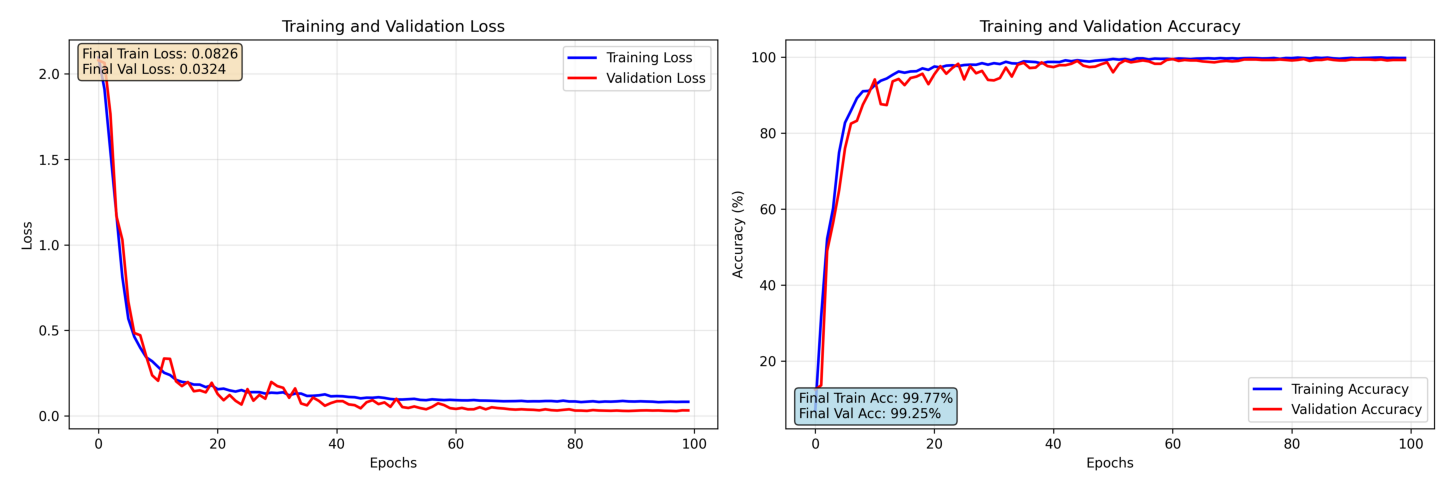

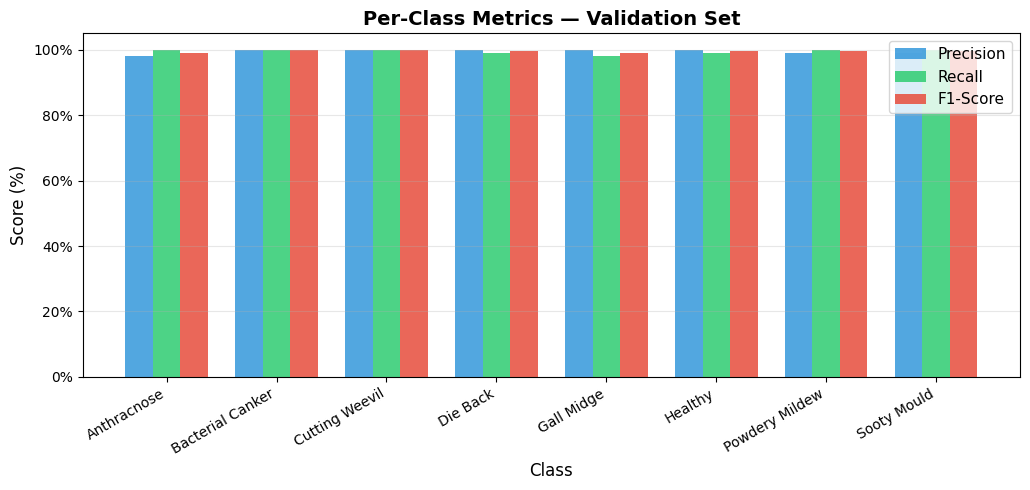

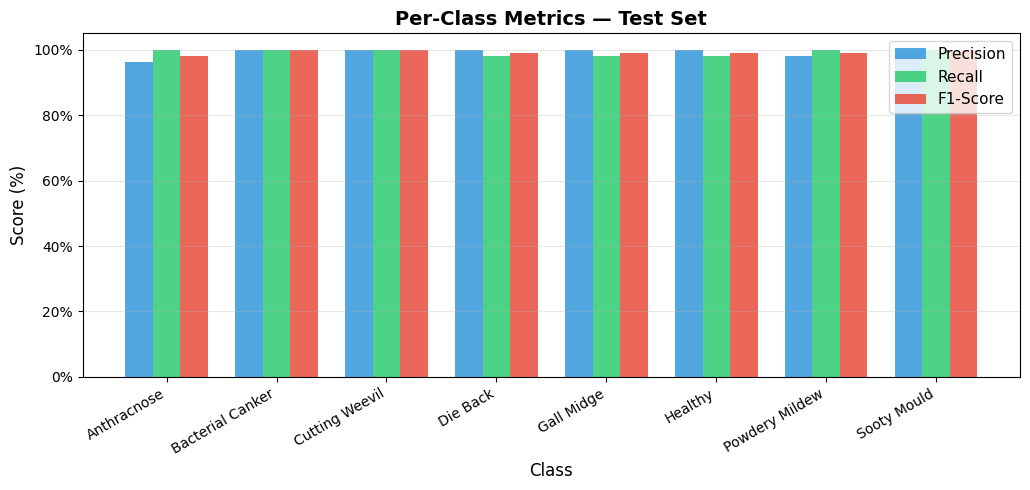

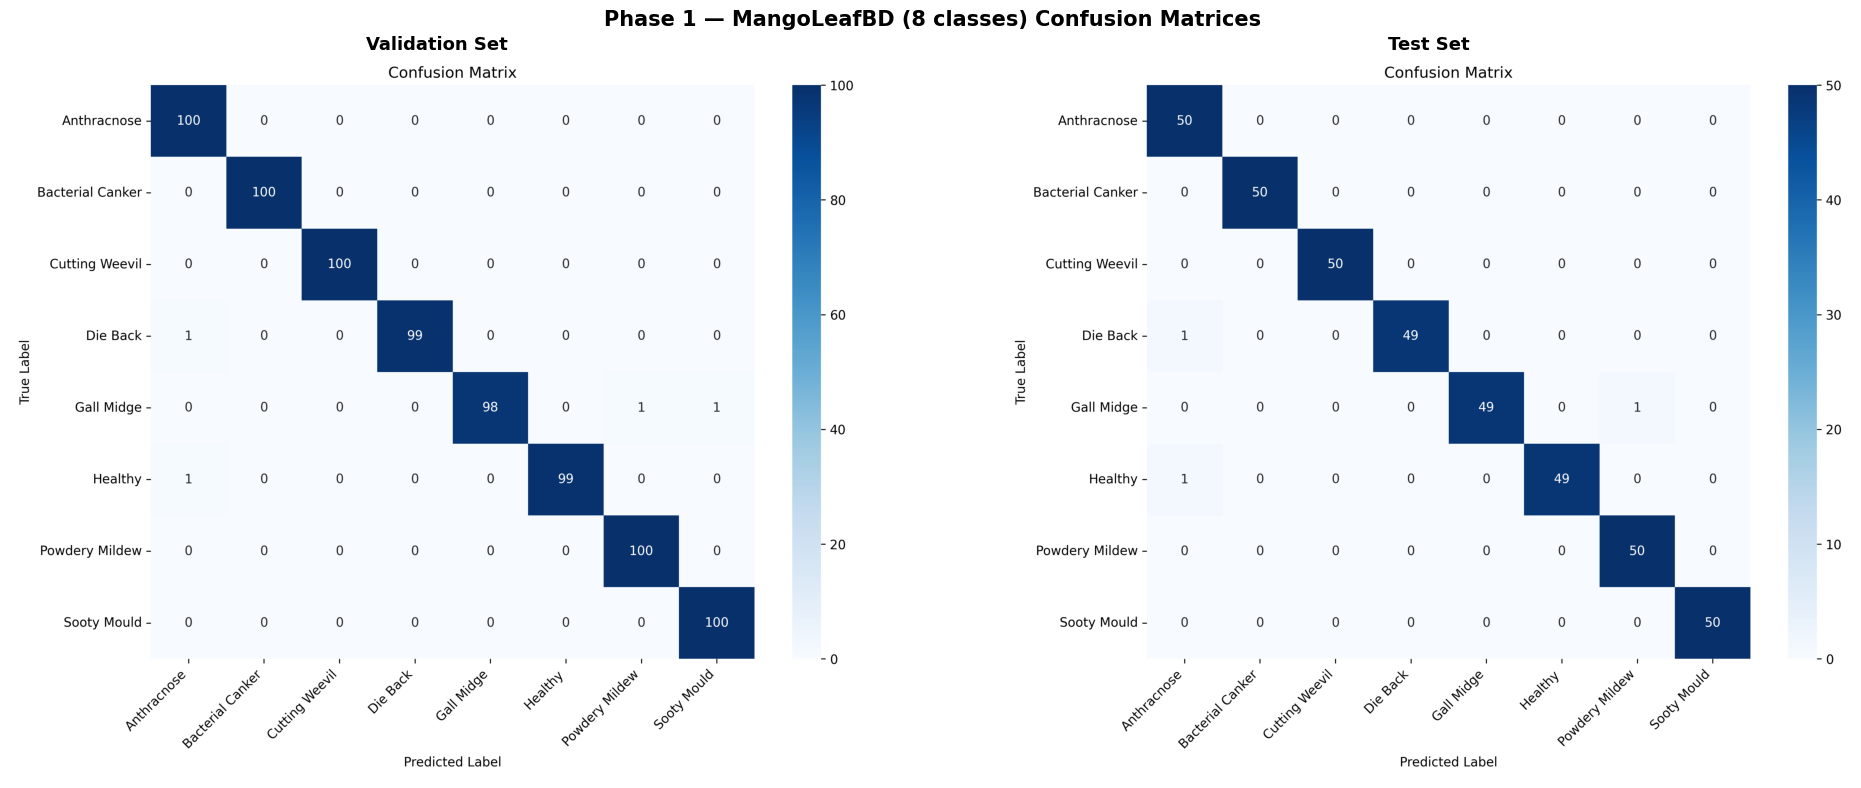

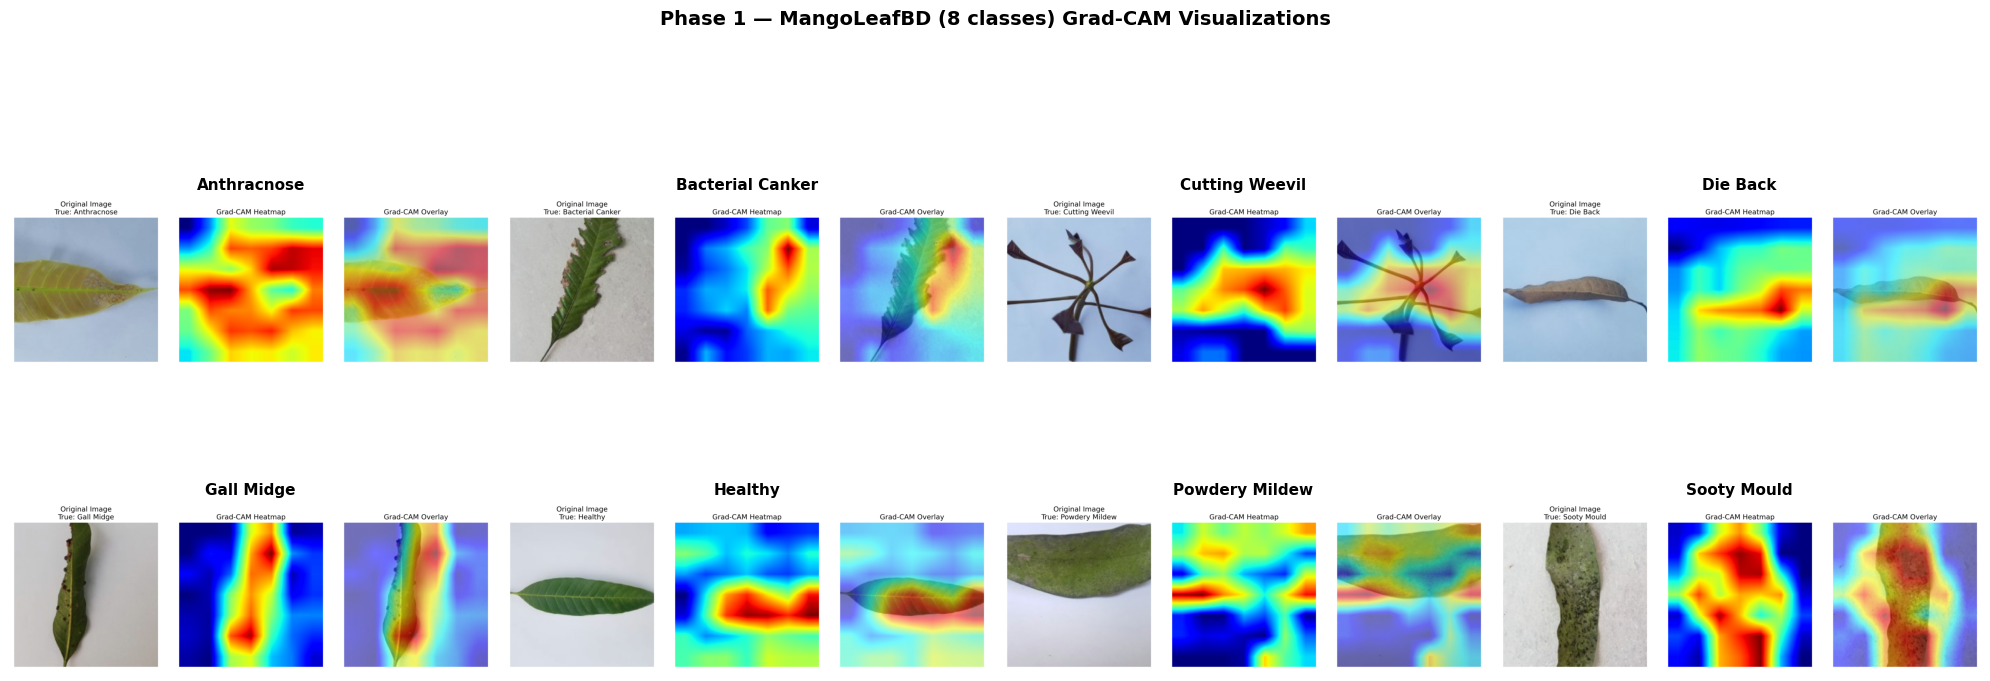

In [8]:
ensure_project_root()

PHASE1_CLASSES_8 = [
    'Anthracnose', 'Bacterial Canker', 'Cutting Weevil',
    'Die Back', 'Gall Midge', 'Healthy', 'Powdery Mildew', 'Sooty Mould'
]

p1_info = display_phase_results(
    output_dir_pattern='./output_phase1/mangoleafbd_phase1-*',
    phase_label='Phase 1 — MangoLeafBD (8 classes)',
    class_names=PHASE1_CLASSES_8
)

if p1_info:
    P1_RUN_DIR, P1_RESULTS = p1_info

---
## Phase 2: Fine-tune on Combined Dataset (8 classes)

**Purpose:** Expose model to diverse illumination, capture devices, and lesion morphology.

Uses the best checkpoint from Phase 1.

In [9]:
import os, glob, subprocess

root = ensure_project_root()

ckpt_matches = sorted(glob.glob(os.path.join(root, 'output_phase1/mangoleafbd_phase1-*/model_best.pth.tar')))
if ckpt_matches:
    ckpt = ckpt_matches[-1]
    print(f'Using Phase 1 checkpoint: {ckpt}')
else:
    print('WARNING: Phase 1 checkpoint not found! Training from scratch.')
    ckpt = None

workers = dataloader_workers(batch_size=256)
cmd = [
    'python3', 'train_mango_mamba.py',
    '--epochs=100',
    '--batch-size=256',
    f'--workers={workers}',
    '--data_dir=datasets/combined_dataset',
    '--lr=5e-4',
    '--min-lr=5e-6',
    '--warmup-epochs=5',
    '--patience-epochs=20',
    '--num-classes=8',
    '--output=./output_phase2',
    '--experiment=combined_phase2',
    '--smoothing=0.01',
    '--drop-path-rate=0.01',
    '--seed=42',
    '--amp',
]
if ckpt:
    cmd.extend(['--train-from-checkpoint', f'--checkpoint-path={ckpt}'])

subprocess.run(cmd, check=True, cwd=root)
print('Phase 2 training complete.')

Using Phase 1 checkpoint: /app/output_phase1/mangoleafbd_phase1-20260705-123530/model_best.pth.tar
[OK] /dev/shm=8.00 GB -- using --workers=2


/opt/venv/lib/python3.12/site-packages/timm/utils/cuda.py:50: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  self._scaler = torch.cuda.amp.GradScaler()
Using native Torch AMP for mixed precision training.
Data processing configuration for current model + dataset:
	input_size: (3, 224, 224)
	interpolation: bicubic
	mean: (0.485, 0.456, 0.406)
	std: (0.229, 0.224, 0.225)
	crop_pct: 0.875
	crop_mode: center
Starting training for 100 epochs...


Loading checkpoint from: /app/output_phase1/mangoleafbd_phase1-20260705-123530/model_best.pth.tar
Checkpoint keys: ['epoch', 'arch', 'state_dict', 'optimizer', 'version', 'args', 'amp_scaler', 'metric']
Checkpoint loaded successfully.

Model Parameters:
  Total parameters: 5,810,428
  Trainable parameters: 5,810,428
  Model size: 22.17 MB (float32)



Train: 0 [   0/125 (  0%)] Loss: 3.776 (3.78) Acc@1: 21.5 (21.5) Time: 20.423s LR: 1.000e-05 Data: 0.629s
Train: 0 [  50/125 ( 40%)] Loss: 2.935 (3.20) Acc@1: 24.2 (24.2) Time: 2.183s LR: 1.000e-05 Data: 0.001s
Train: 0 [ 100/125 ( 81%)] Loss: 2.038 (2.81) Acc@1: 35.5 (28.2) Time: 2.180s LR: 1.000e-05 Data: 0.001s
Test: [   0/15] Time: 0.741 (0.741) Loss:  1.2346 (1.2346) Acc@1: 64.4531 (64.4531)
Current checkpoints:
 ('./output_phase2/combined_phase2-20260705-132227/checkpoint-0.pth.tar', 43.675)

Epoch 1/100 - Train Loss: 2.6532 - Val Acc: 43.6750 - Best Acc: 43.6750 (epoch 1) - Val Loss: 1.8822 (best: 1.8822) - Patience: 0/20
Train: 1 [   0/125 (  0%)] Loss: 1.910 (1.91) Acc@1: 43.4 (43.4) Time: 2.892s LR: 1.080e-04 Data: 0.336s
Train: 1 [  50/125 ( 40%)] Loss: 1.130 (1.29) Acc@1: 60.5 (58.4) Time: 2.178s LR: 1.080e-04 Data: 0.001s
Train: 1 [ 100/125 ( 81%)] Loss: 0.9508 (1.12) Acc@1: 69.1 (63.0) Time: 2.183s LR: 1.080e-04 Data: 0.001s
Test: [   0/15] Time: 0.551 (0.551) Loss:  0.50

Lightweight checkpoint saved to: ./output_phase2/combined_phase2-20260705-132227/model_best_inference.pth
Lightweight checkpoint saved to: ./output_phase2/combined_phase2-20260705-132227/model_best_inference.pth
Lightweight checkpoint saved to: ./output_phase2/combined_phase2-20260705-132227/model_best_inference.pth
Lightweight checkpoint saved to: ./output_phase2/combined_phase2-20260705-132227/model_best_inference.pth
Lightweight checkpoint saved to: ./output_phase2/combined_phase2-20260705-132227/model_best_inference.pth
Lightweight checkpoint saved to: ./output_phase2/combined_phase2-20260705-132227/model_best_inference.pth
Lightweight checkpoint saved to: ./output_phase2/combined_phase2-20260705-132227/model_best_inference.pth
Lightweight checkpoint saved to: ./output_phase2/combined_phase2-20260705-132227/model_best_inference.pth
Lightweight checkpoint saved to: ./output_phase2/combined_phase2-20260705-132227/model_best_inference.pth
Lightweight checkpoint saved to: ./output_phas

Test: [   0/15] Time: 0.782 (0.782) Loss:  0.0099 (0.0099) Acc@1: 100.0000 (100.0000)
Training completed! Best validation accuracy: 99.7750 (epoch 98)
Total training time: 7h 45m 6s
Model parameters: 5,810,428 trainable / 5,810,428 total
Early stopping: Not triggered (patience: 20 epochs, monitor: loss)
Best model metrics - Train Acc: 99.83% | Val Acc: 99.78% | Test Acc: 99.67%
Best model metrics - Train Loss: 0.0726 | Val Loss: 0.0149 | Test Loss: 0.0213
Validation metrics - Accuracy: 0.9980 | Precision: 0.9980 | Recall: 0.9980 | F1: 0.9980
Test metrics - Accuracy: 0.9960 | Precision: 0.9960 | Recall: 0.9960 | F1: 0.9960
Training results saved to: ./output_phase2/combined_phase2-20260705-132227/training_results.json
Checkpoints saved: Full (model_best.pth.tar, last.pth.tar) | Lightweight (model_best_inference.pth, model_last_inference.pth)
Visualizations generated: Grad-CAM heatmaps per class, confusion matrices (val+test), training curves


Loading best model from epoch 98 for final evaluation...
Best model loaded successfully. Best accuracy: 99.7750
Confusion matrix saved to: ./output_phase2/combined_phase2-20260705-132227/confusion_matrix_val.png
Confusion matrix saved to: ./output_phase2/combined_phase2-20260705-132227/confusion_matrix_test.png
Generating Grad-CAM visualizations...
Using target layer: BatchNorm2d(384, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
Grad-CAM initialized successfully with model wrapper
Generating Grad-CAM for class Anthracnose (class 0)
Generated Grad-CAM visualization for class Anthracnose
Generating Grad-CAM for class Bacterial Canker (class 1)
Generated Grad-CAM visualization for class Bacterial Canker
Generating Grad-CAM for class Cutting Weevil (class 2)
Generated Grad-CAM visualization for class Cutting Weevil
Generating Grad-CAM for class Die Back (class 3)
Generated Grad-CAM visualization for class Die Back
Generating Grad-CAM for class Gall Midge (clas

### Phase 2 Results — Inline Visualizations

Loading from: ./output_phase2/combined_phase2-20260705-132227


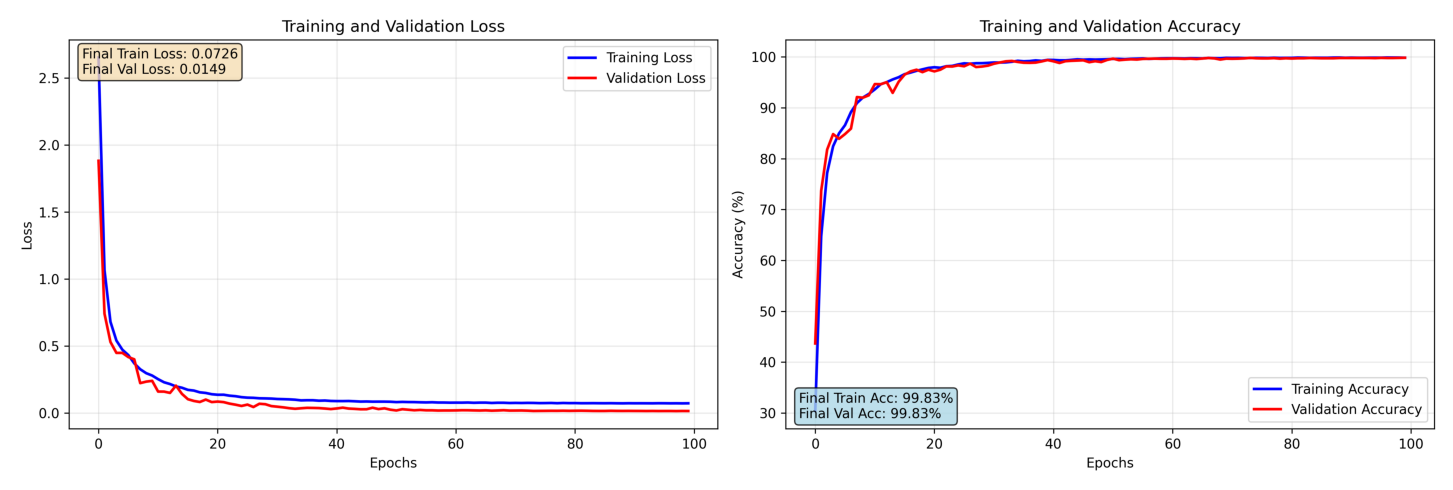

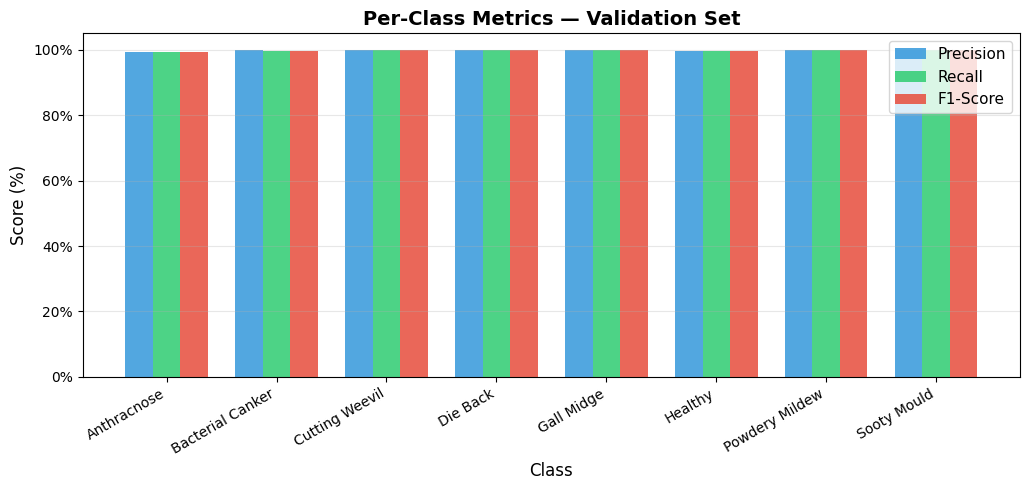

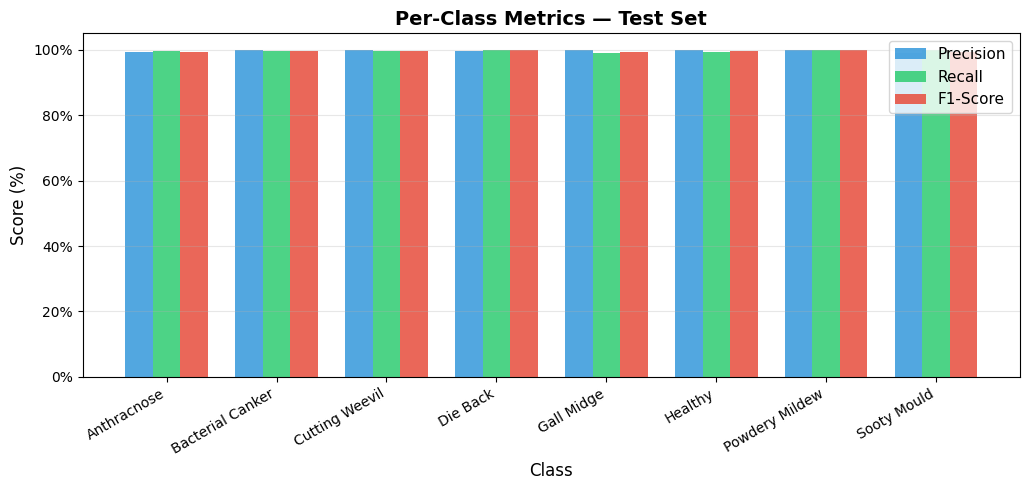

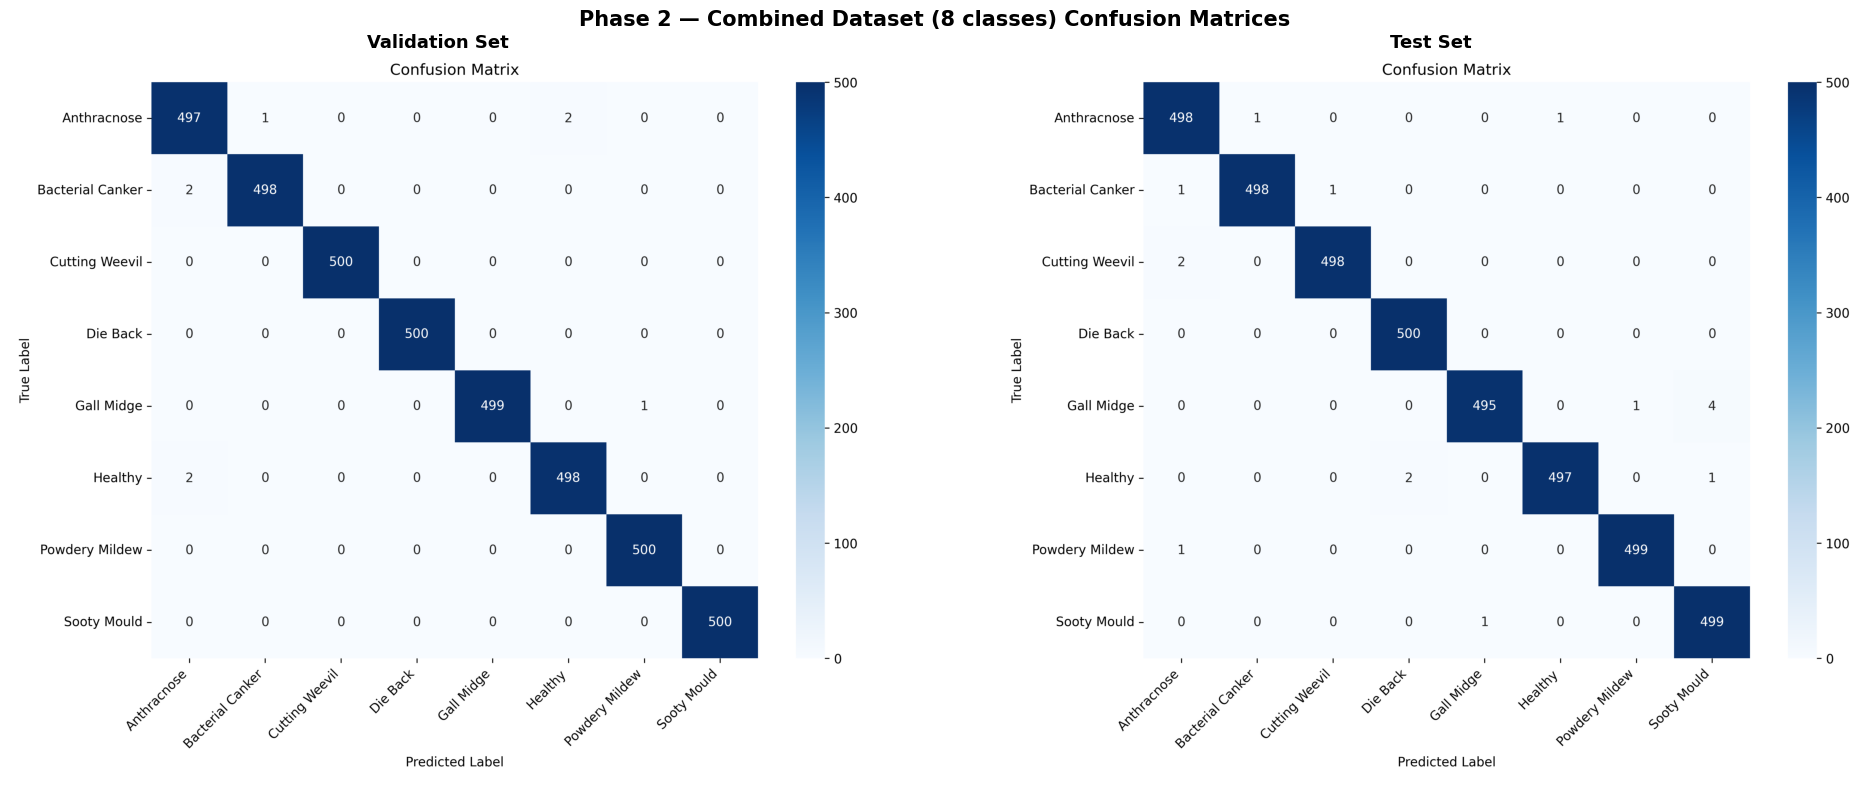

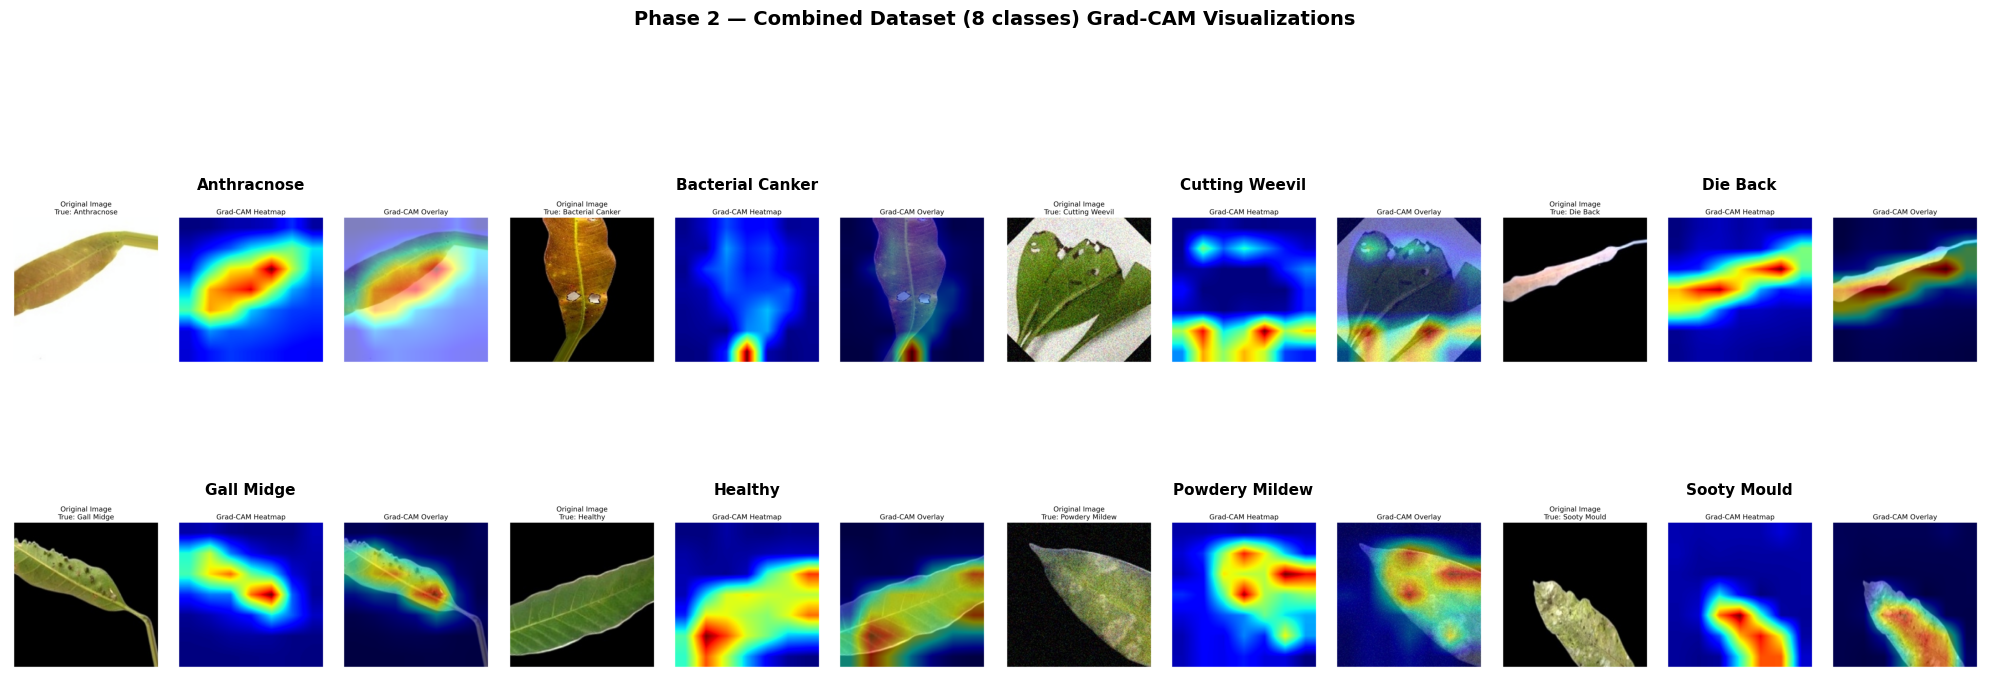

In [10]:
ensure_project_root()

PHASE2_CLASSES_8 = [
    'Anthracnose', 'Bacterial Canker', 'Cutting Weevil',
    'Die Back', 'Gall Midge', 'Healthy', 'Powdery Mildew', 'Sooty Mould'
]

p2_info = display_phase_results(
    output_dir_pattern='./output_phase2/combined_phase2-*',
    phase_label='Phase 2 — Combined Dataset (8 classes)',
    class_names=PHASE2_CLASSES_8
)

if p2_info:
    P2_RUN_DIR, P2_RESULTS = p2_info

---
## Phase 3: Fine-tune on VN-MangoLeaf (7 classes)

**Purpose:** Adapt to Vietnamese mango varieties (7 classes: Anthracnose, Dieback, Gall Midge, Healthy, Powdery Mildew, Red Rust, Sooty Mold).

Replaces the classification head (8→7 classes). Training script auto-handles the size mismatch.

In [11]:
import os, glob, subprocess

root = ensure_project_root()

ckpt_matches = sorted(glob.glob(os.path.join(root, 'output_phase2/combined_phase2-*/model_best.pth.tar')))
if ckpt_matches:
    ckpt = ckpt_matches[-1]
    print(f'Using Phase 2 checkpoint: {ckpt}')
else:
    print('WARNING: Phase 2 checkpoint not found! Training from scratch.')
    ckpt = None

workers = dataloader_workers(batch_size=256)
cmd = [
    'python3', 'train_mango_mamba.py',
    '--epochs=100',
    '--batch-size=256',
    f'--workers={workers}',
    '--data_dir=datasets/vn_mangoleaf',
    '--lr=5e-4',
    '--min-lr=5e-6',
    '--warmup-epochs=5',
    '--patience-epochs=20',
    '--num-classes=7',
    '--output=./output_phase3',
    '--experiment=vnmangoleaf_phase3',
    '--smoothing=0.01',
    '--drop-path-rate=0.01',
    '--seed=42',
    '--amp',
]
if ckpt:
    cmd.extend(['--train-from-checkpoint', f'--checkpoint-path={ckpt}'])

subprocess.run(cmd, check=True, cwd=root)
print('Phase 3 training complete.')

Using Phase 2 checkpoint: /app/output_phase2/combined_phase2-20260705-132227/model_best.pth.tar
[OK] /dev/shm=8.00 GB -- using --workers=2


/opt/venv/lib/python3.12/site-packages/timm/utils/cuda.py:50: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  self._scaler = torch.cuda.amp.GradScaler()
Using native Torch AMP for mixed precision training.
Data processing configuration for current model + dataset:
	input_size: (3, 224, 224)
	interpolation: bicubic
	mean: (0.485, 0.456, 0.406)
	std: (0.229, 0.224, 0.225)
	crop_pct: 0.875
	crop_mode: center
Starting training for 100 epochs...


Loading checkpoint from: /app/output_phase2/combined_phase2-20260705-132227/model_best.pth.tar
Checkpoint keys: ['epoch', 'arch', 'state_dict', 'optimizer', 'version', 'args', 'amp_scaler', 'metric']
Size mismatch detected in head layer (likely different number of classes).
Current model classes: 7
Checkpoint classes: 8
Removing incompatible key: head.weight (shape: torch.Size([8, 384]))
Removing incompatible key: head.bias (shape: torch.Size([8]))
Loaded checkpoint with partial weights:
  Missing keys (will be randomly initialized): ['head.weight', 'head.bias']
Note: The classification head layer will be randomly initialized for 7 classes.
This is normal when transferring between datasets with different numbers of classes.

Model Parameters:
  Total parameters: 5,810,043
  Trainable parameters: 5,810,043
  Model size: 22.16 MB (float32)



Train: 0 [   0/21 (  0%)] Loss: 1.962 (1.96) Acc@1: 14.5 (14.5) Time: 20.509s LR: 1.000e-05 Data: 0.661s
Test: [   0/2] Time: 0.791 (0.791) Loss:  1.8990 (1.8990) Acc@1: 31.2500 (31.2500)
Current checkpoints:
 ('./output_phase3/vnmangoleaf_phase3-20260705-210739/checkpoint-0.pth.tar', 20.999999945504324)

Epoch 1/100 - Train Loss: 1.9112 - Val Acc: 21.0000 - Best Acc: 21.0000 (epoch 1) - Val Loss: 1.8958 (best: 1.8958) - Patience: 0/20
Train: 1 [   0/21 (  0%)] Loss: 1.876 (1.88) Acc@1: 30.1 (30.1) Time: 2.955s LR: 1.080e-04 Data: 0.368s
Test: [   0/2] Time: 0.577 (0.577) Loss:  1.1741 (1.1741) Acc@1: 58.2031 (58.2031)
Current checkpoints:
 ('./output_phase3/vnmangoleaf_phase3-20260705-210739/checkpoint-1.pth.tar', 78.42857016427176)
 ('./output_phase3/vnmangoleaf_phase3-20260705-210739/checkpoint-0.pth.tar', 20.999999945504324)

Epoch 2/100 - Train Loss: 1.4160 - Val Acc: 78.4286 - Best Acc: 78.4286 (epoch 2) - Val Loss: 0.9745 (best: 0.9745) - Patience: 0/20
Train: 2 [   0/21 (  0%)]

Lightweight checkpoint saved to: ./output_phase3/vnmangoleaf_phase3-20260705-210739/model_best_inference.pth
Lightweight checkpoint saved to: ./output_phase3/vnmangoleaf_phase3-20260705-210739/model_best_inference.pth
Lightweight checkpoint saved to: ./output_phase3/vnmangoleaf_phase3-20260705-210739/model_best_inference.pth
Lightweight checkpoint saved to: ./output_phase3/vnmangoleaf_phase3-20260705-210739/model_best_inference.pth
Lightweight checkpoint saved to: ./output_phase3/vnmangoleaf_phase3-20260705-210739/model_best_inference.pth
Lightweight checkpoint saved to: ./output_phase3/vnmangoleaf_phase3-20260705-210739/model_best_inference.pth
Lightweight checkpoint saved to: ./output_phase3/vnmangoleaf_phase3-20260705-210739/model_best_inference.pth
Lightweight checkpoint saved to: ./output_phase3/vnmangoleaf_phase3-20260705-210739/model_best_inference.pth
Lightweight checkpoint saved to: ./output_phase3/vnmangoleaf_phase3-20260705-210739/model_best_inference.pth
Lightweight checkpo

Test: [   0/2] Time: 0.776 (0.776) Loss:  0.1167 (0.1167) Acc@1: 96.8750 (96.8750)
Training completed! Best validation accuracy: 97.5714 (epoch 73)
Total training time: 1h 13m 53s
Model parameters: 5,810,043 trainable / 5,810,043 total
Early stopping: Triggered (patience: 20 epochs, monitor: loss)
Best model metrics - Train Acc: 99.89% | Val Acc: 97.57% | Test Acc: 98.71%
Best model metrics - Train Loss: 0.0695 | Val Loss: 0.0837 | Test Loss: 0.0571
Validation metrics - Accuracy: 0.9771 | Precision: 0.9776 | Recall: 0.9771 | F1: 0.9772
Test metrics - Accuracy: 0.9771 | Precision: 0.9769 | Recall: 0.9771 | F1: 0.9767
Training results saved to: ./output_phase3/vnmangoleaf_phase3-20260705-210739/training_results.json
Checkpoints saved: Full (model_best.pth.tar, last.pth.tar) | Lightweight (model_best_inference.pth, model_last_inference.pth)
Visualizations generated: Grad-CAM heatmaps per class, confusion matrices (val+test), training curves


Loading best model from epoch 73 for final evaluation...
Best model loaded successfully. Best accuracy: 97.5714
Confusion matrix saved to: ./output_phase3/vnmangoleaf_phase3-20260705-210739/confusion_matrix_val.png
Confusion matrix saved to: ./output_phase3/vnmangoleaf_phase3-20260705-210739/confusion_matrix_test.png
Generating Grad-CAM visualizations...
Using target layer: BatchNorm2d(384, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
Grad-CAM initialized successfully with model wrapper
Generating Grad-CAM for class Anthracnose (class 0)
Generated Grad-CAM visualization for class Anthracnose
Generating Grad-CAM for class Dieback (class 1)
Generated Grad-CAM visualization for class Dieback
Generating Grad-CAM for class Gall Midge (class 2)
Generated Grad-CAM visualization for class Gall Midge
Generating Grad-CAM for class Healthy (class 3)
Generated Grad-CAM visualization for class Healthy
Generating Grad-CAM for class Powdery Mildew (class 4)
Generated Gra

### Phase 3 Results — Inline Visualizations

Loading from: ./output_phase3/vnmangoleaf_phase3-20260705-210739


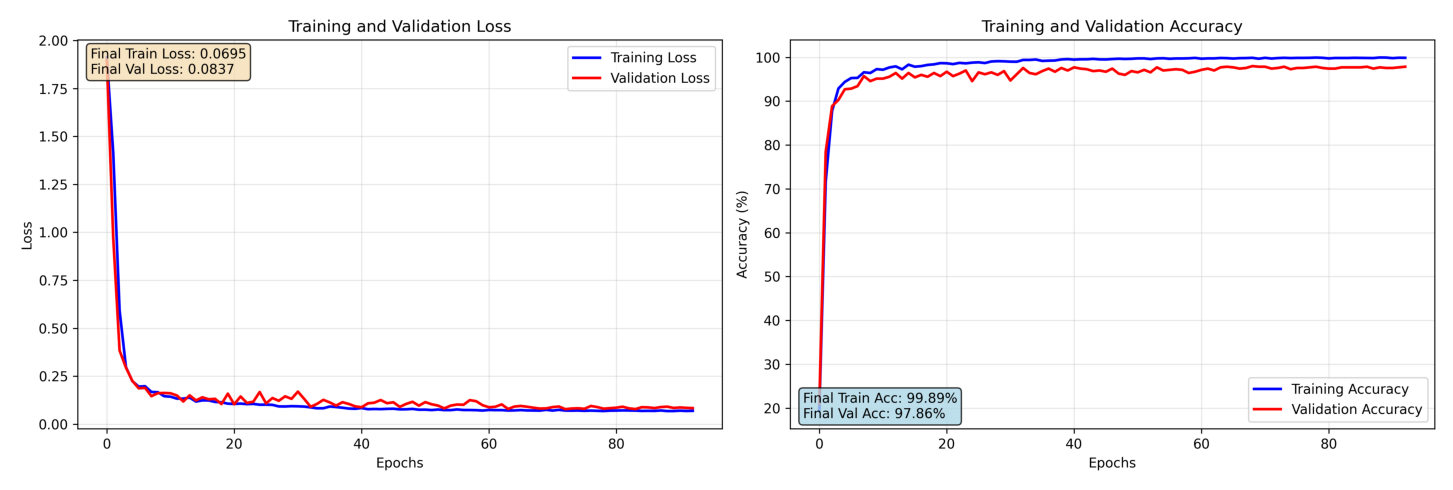

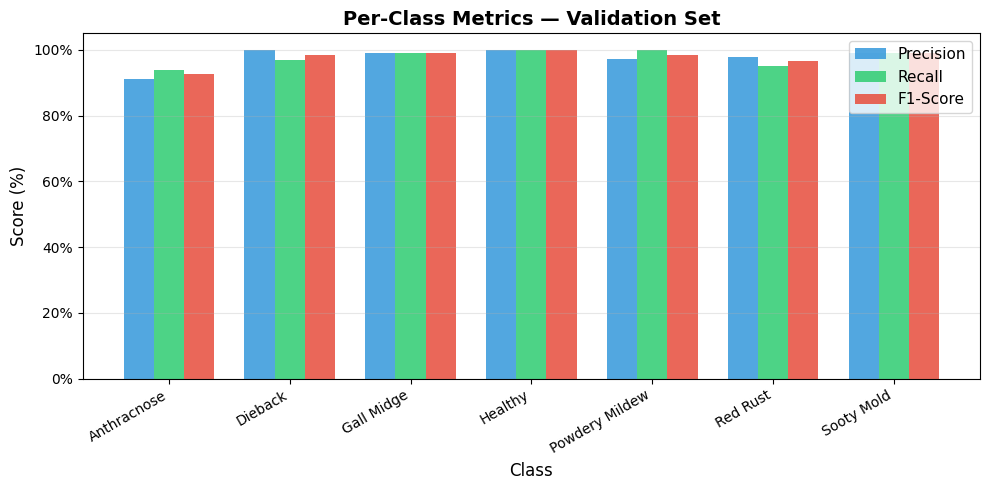

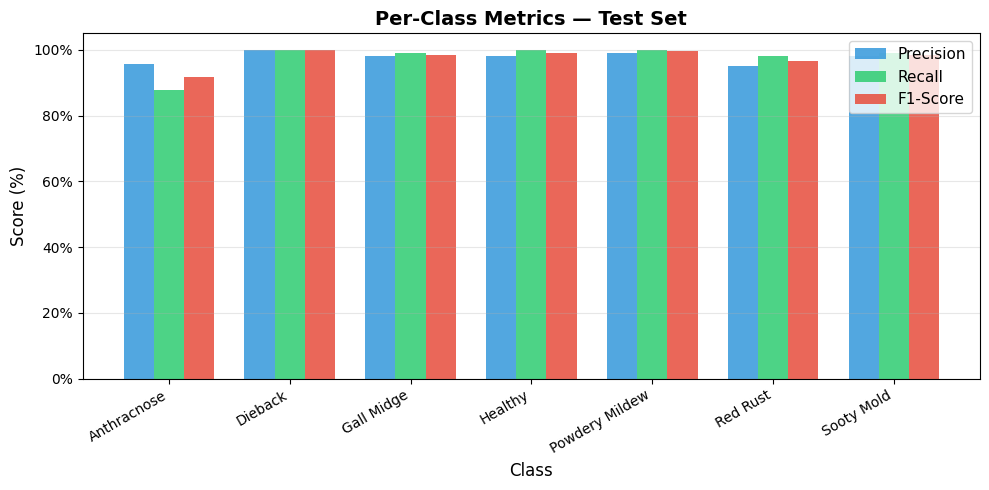

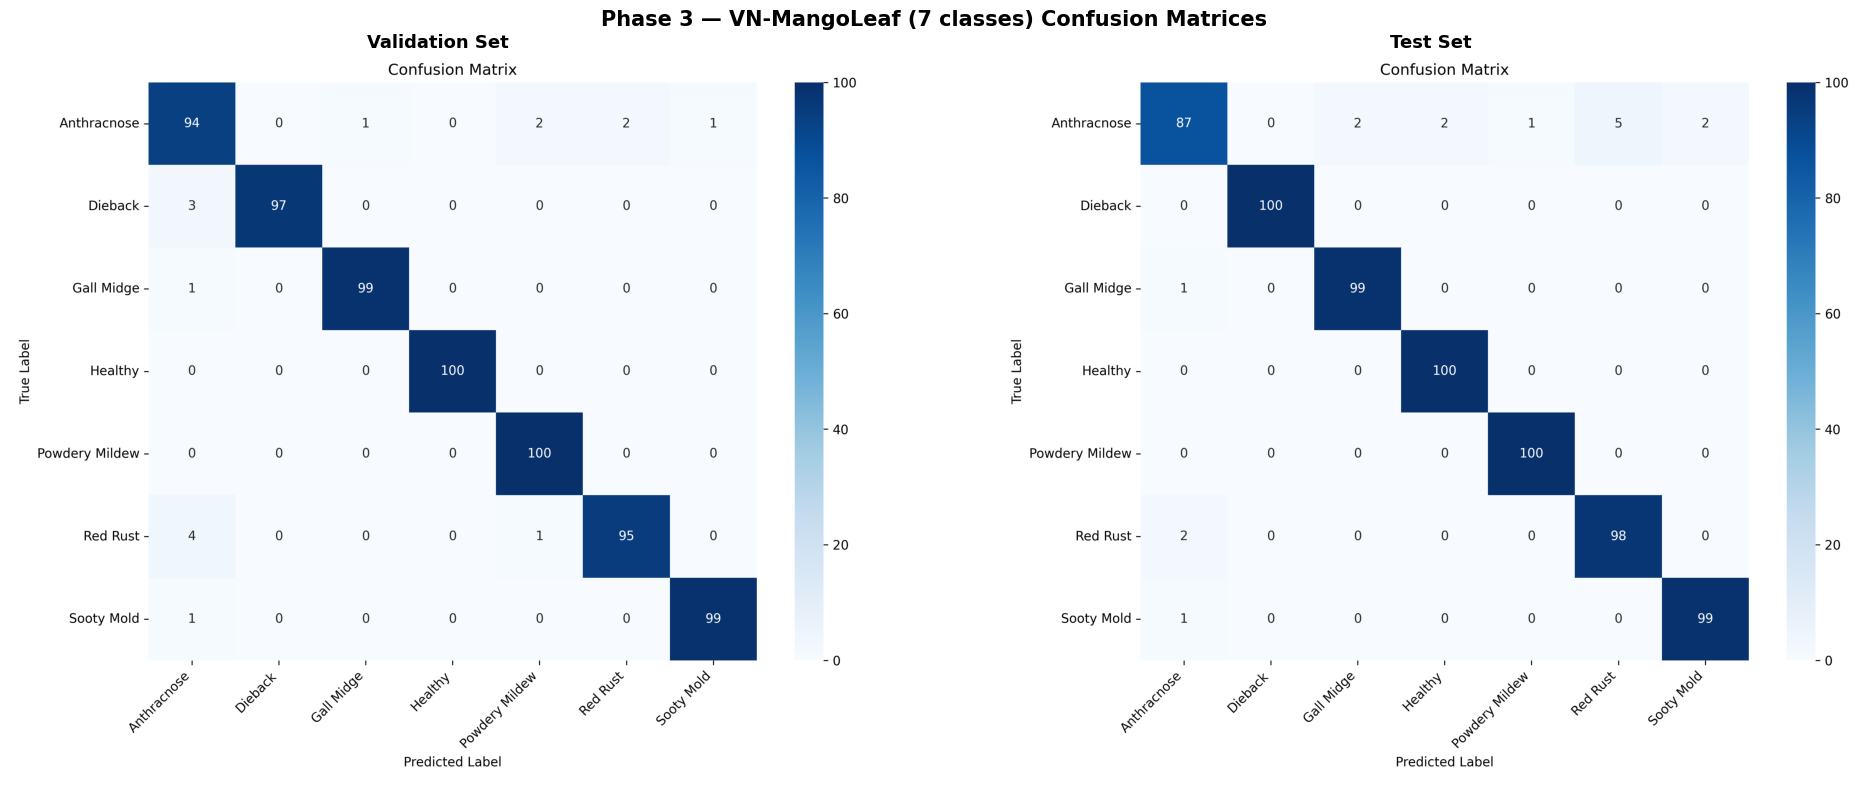

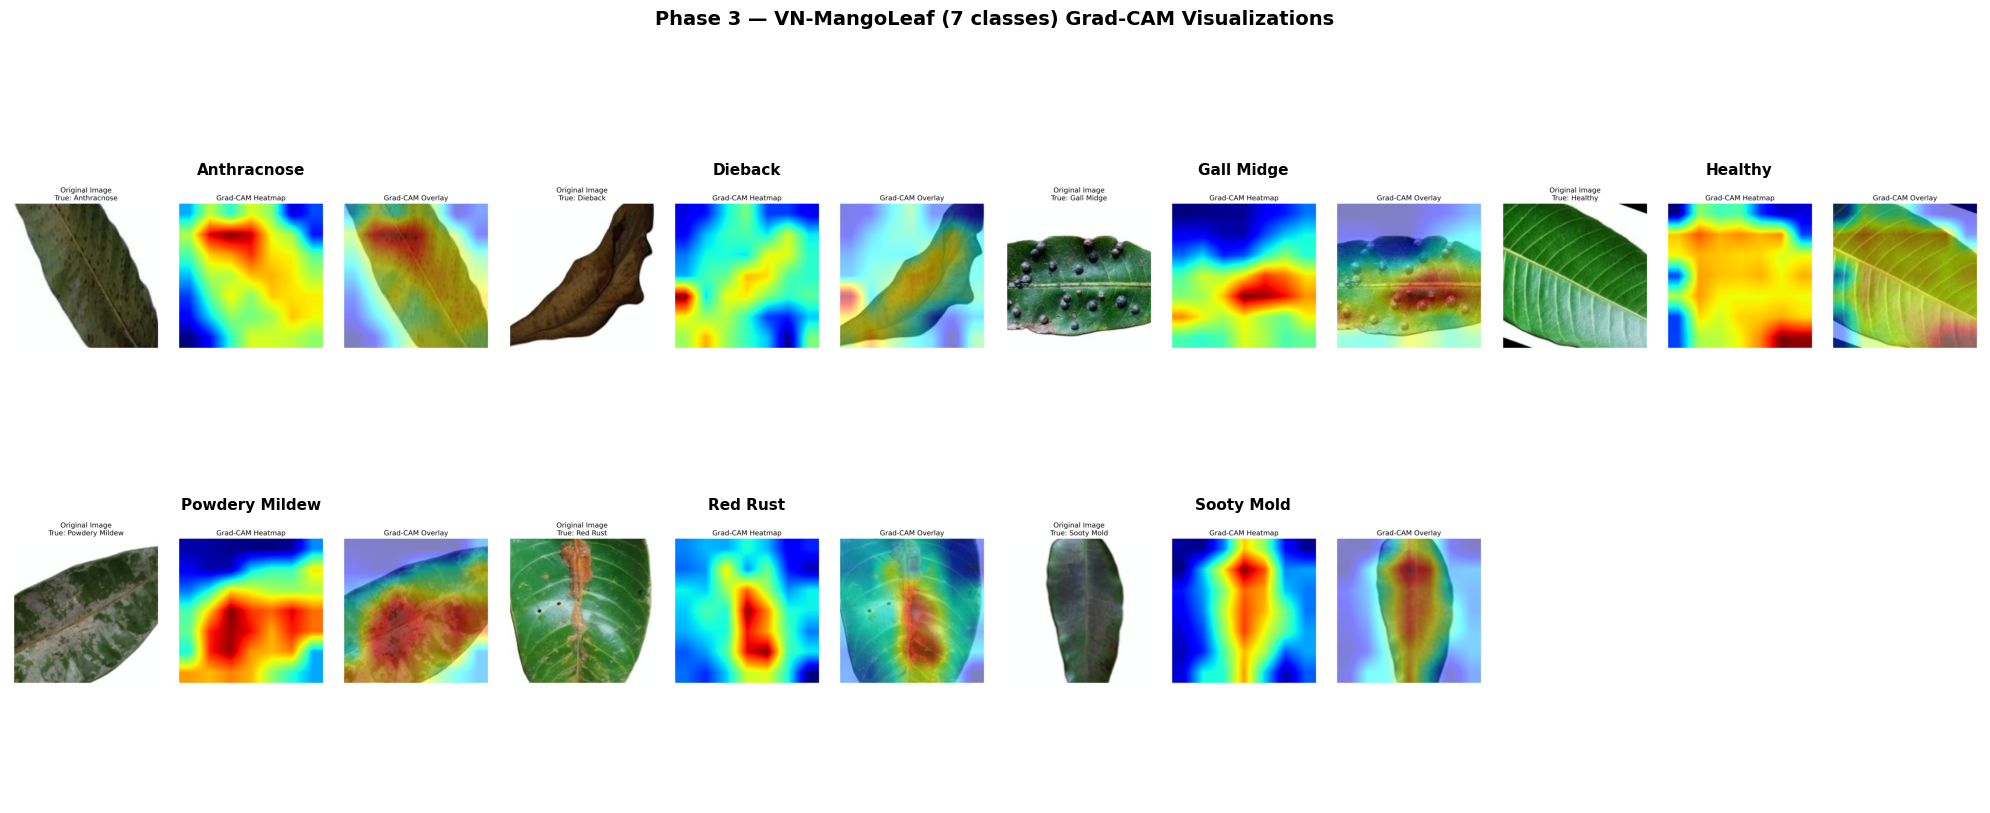

In [12]:
ensure_project_root()

PHASE3_CLASSES_7 = [
    'Anthracnose', 'Dieback', 'Gall Midge',
    'Healthy', 'Powdery Mildew', 'Red Rust', 'Sooty Mold'
]

p3_info = display_phase_results(
    output_dir_pattern='./output_phase3/vnmangoleaf_phase3-*',
    phase_label='Phase 3 — VN-MangoLeaf (7 classes)',
    class_names=PHASE3_CLASSES_7
)

if p3_info:
    P3_RUN_DIR, P3_RESULTS = p3_info

---
## Section 6: Throughput Measurement

Measures inference throughput (images/sec) and latency (ms/image) across batch sizes 1, 8, 32, 64.
Results and plots are saved to the Phase 3 (or latest) output folder.


── Phase 3 (7-cls) ──
  Loaded: model_best_inference.pth (7 classes)
  Batch   1: 183.3 img/s  |  5.455 ms/img
  Batch   8: 726.4 img/s  |  1.377 ms/img
  Batch  32: 924.4 img/s  |  1.082 ms/img
  Batch  64: 869.3 img/s  |  1.150 ms/img

── Phase 1 (8-cls) ──
  Loaded: model_best_inference.pth (8 classes)
  Batch   1: 184.4 img/s  |  5.423 ms/img
  Batch   8: 722.3 img/s  |  1.384 ms/img
  Batch  32: 927.2 img/s  |  1.079 ms/img
  Batch  64: 874.3 img/s  |  1.144 ms/img
Throughput plot saved: ./output_phase3/vnmangoleaf_phase3-20260705-210739/throughput_measurement.png


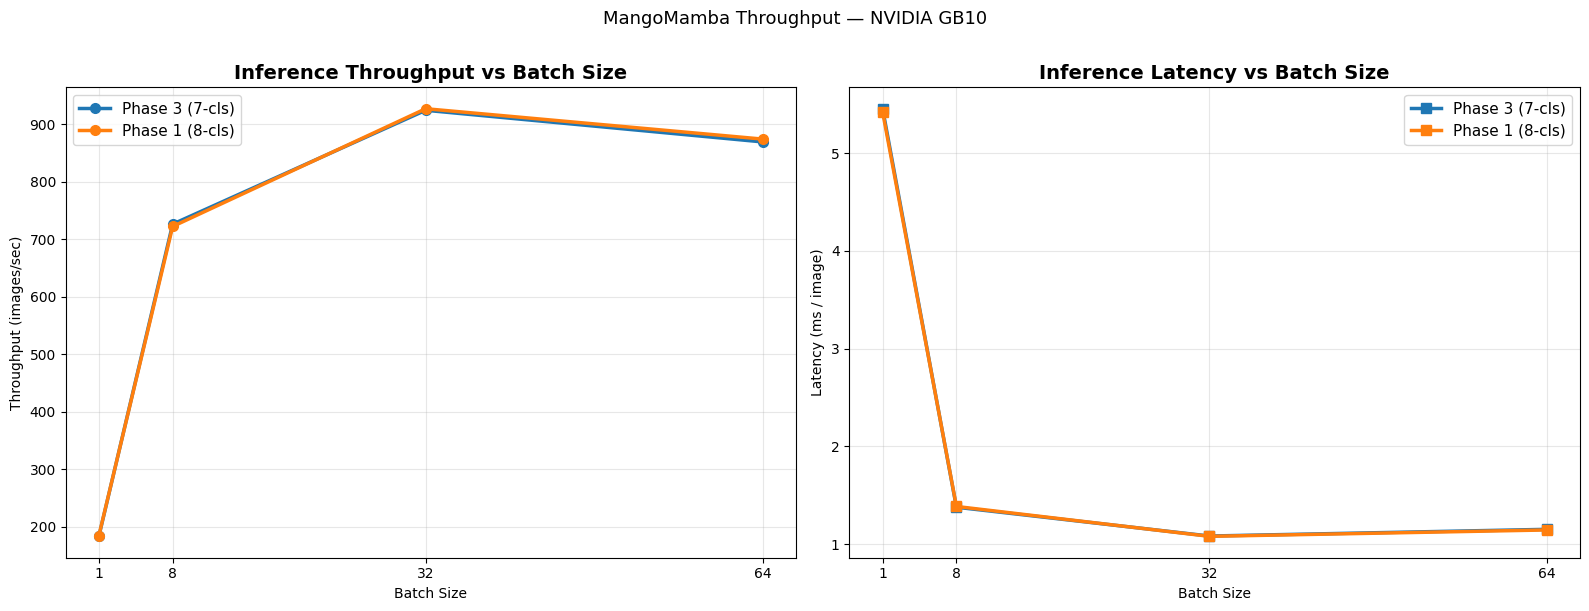

Model,Batch,Throughput (img/s),Latency (ms/img),Latency (ms/batch)
Phase 3 (7-cls),1,183.3,5.455,5.45
Phase 3 (7-cls),8,726.4,1.377,11.01
Phase 3 (7-cls),32,924.4,1.082,34.62
Phase 3 (7-cls),64,869.3,1.150,73.62
Phase 1 (8-cls),1,184.4,5.423,5.42
Phase 1 (8-cls),8,722.3,1.384,11.08
Phase 1 (8-cls),32,927.2,1.079,34.51
Phase 1 (8-cls),64,874.3,1.144,73.21


In [13]:
import os, glob, json, time
import numpy as np
import matplotlib.pyplot as plt
import torch
from IPython.display import display, HTML

ensure_project_root()


def load_inference_checkpoint(ckpt_path, num_classes):
    from models.mango_mamba import mango_mamba_tiny
    model = mango_mamba_tiny(num_classes=num_classes)
    ckpt = torch.load(ckpt_path, map_location='cpu', weights_only=False)
    sd = ckpt.get('model_state_dict', ckpt.get('state_dict', ckpt))
    model.load_state_dict(sd, strict=True)
    print(f'  Loaded: {os.path.basename(ckpt_path)} ({num_classes} classes)')
    return model


def measure_throughput_batch(model, batch_size, resolution=224, warmup=50, runs=200):
    model.cuda().eval()
    dummy = torch.randn(batch_size, 3, resolution, resolution, device='cuda')
    with torch.no_grad(), torch.amp.autocast('cuda'):
        for _ in range(warmup):
            model(dummy)
    torch.cuda.synchronize()
    timings = []
    with torch.no_grad(), torch.amp.autocast('cuda'):
        for _ in range(runs):
            t0 = time.perf_counter()
            model(dummy)
            torch.cuda.synchronize()
            timings.append(time.perf_counter() - t0)
    timings = np.array(timings)
    lo, hi = np.percentile(timings, 5), np.percentile(timings, 95)
    trimmed = timings[(timings >= lo) & (timings <= hi)]
    return {
        'batch_size': batch_size,
        'throughput_img_per_sec': batch_size / trimmed.mean(),
        'latency_ms_per_img': trimmed.mean() * 1000 / batch_size,
        'latency_ms_per_batch': trimmed.mean() * 1000,
    }


p3_ckpts = sorted(glob.glob('./output_phase3/vnmangoleaf_phase3-*/model_best_inference.pth'))
p1_ckpts = sorted(glob.glob('./output_phase1/mangoleafbd_phase1-*/model_best_inference.pth'))

throughput_configs = []
if p3_ckpts:
    throughput_configs.append((p3_ckpts[-1], 7, 'Phase 3 (7-cls)'))
if p1_ckpts:
    throughput_configs.append((p1_ckpts[-1], 8, 'Phase 1 (8-cls)'))

if not throughput_configs:
    print('[ERROR] No inference checkpoints found. Run training phases first.')
else:
    BATCH_SIZES = [1, 8, 32, 64]
    all_results = {}

    for ckpt_path, num_cls, label in throughput_configs:
        print(f'\n── {label} ──')
        model = load_inference_checkpoint(ckpt_path, num_cls)
        phase_results = []
        for bs in BATCH_SIZES:
            print(f'  Batch {bs:>3d}: ', end='', flush=True)
            try:
                r = measure_throughput_batch(model, bs)
                phase_results.append(r)
                print(f"{r['throughput_img_per_sec']:.1f} img/s  |  {r['latency_ms_per_img']:.3f} ms/img")
            except RuntimeError as e:
                print(f'OOM skipped')
        all_results[label] = phase_results
        del model
        torch.cuda.empty_cache()

    # Plot
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    for label, pr in all_results.items():
        bs_vals = [r['batch_size'] for r in pr]
        ax1.plot(bs_vals, [r['throughput_img_per_sec'] for r in pr], marker='o', linewidth=2.5, markersize=7, label=label)
        ax2.plot(bs_vals, [r['latency_ms_per_img'] for r in pr],     marker='s', linewidth=2.5, markersize=7, label=label)
    ax1.set(xlabel='Batch Size', ylabel='Throughput (images/sec)',  title='Inference Throughput vs Batch Size')
    ax2.set(xlabel='Batch Size', ylabel='Latency (ms / image)',     title='Inference Latency vs Batch Size')
    for ax in (ax1, ax2):
        ax.legend(fontsize=11); ax.grid(alpha=0.3); ax.set_xticks(BATCH_SIZES)
    ax1.set_title('Inference Throughput vs Batch Size', fontsize=14, fontweight='bold')
    ax2.set_title('Inference Latency vs Batch Size',    fontsize=14, fontweight='bold')
    plt.suptitle(f'MangoMamba Throughput — {torch.cuda.get_device_name()}', fontsize=13, y=1.01)
    plt.tight_layout()

    save_dir = find_latest_run('./output_phase3/vnmangoleaf_phase3-*') or \
               find_latest_run('./output_phase1/mangoleafbd_phase1-*')
    if save_dir:
        tp_path = os.path.join(save_dir, 'throughput_measurement.png')
        plt.savefig(tp_path, dpi=150, bbox_inches='tight')
        print(f'Throughput plot saved: {tp_path}')
        with open(os.path.join(save_dir, 'throughput_results.json'), 'w') as f:
            json.dump(all_results, f, indent=2)
    plt.show()

    # Summary table
    rows = ''
    bg = ['#ecf0f1', 'white']
    i = 0
    for label, pr in all_results.items():
        for r in pr:
            rows += f"<tr style='background:{bg[i%2]};'><td style='padding:6px 12px;'>{label}</td><td style='padding:6px 12px;text-align:center;'>{r['batch_size']}</td><td style='padding:6px 12px;text-align:center;'>{r['throughput_img_per_sec']:.1f}</td><td style='padding:6px 12px;text-align:center;'>{r['latency_ms_per_img']:.3f}</td><td style='padding:6px 12px;text-align:center;'>{r['latency_ms_per_batch']:.2f}</td></tr>"
            i += 1
    display(HTML(f"""
    <h3 style='font-family:sans-serif;'>Throughput Summary</h3>
    <table style='border-collapse:collapse;font-family:sans-serif;font-size:13px;'>
      <thead><tr style='background:#2c3e50;color:white;'>
        <th style='padding:8px 12px;'>Model</th><th style='padding:8px 12px;'>Batch</th>
        <th style='padding:8px 12px;'>Throughput (img/s)</th><th style='padding:8px 12px;'>Latency (ms/img)</th><th style='padding:8px 12px;'>Latency (ms/batch)</th>
      </tr></thead><tbody>{rows}</tbody></table>
    """))

---
## Section 7: Trained Weight Visualization

Two complementary visualizations of the final Phase 3 model:

- **7a — Conv Filter Heatmaps:** Learned filters from patch embedding and downsample convolutions + classifier head weights
- **7b — Feature t-SNE:** 2D t-SNE projection of learned feature vectors from the validation set, colored by class

Loaded: model_best_inference.pth
  Saved: ./output_phase3/vnmangoleaf_phase3-20260705-210739/weight_patch_embed_conv1.png


/tmp/ipykernel_54/4092813049.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


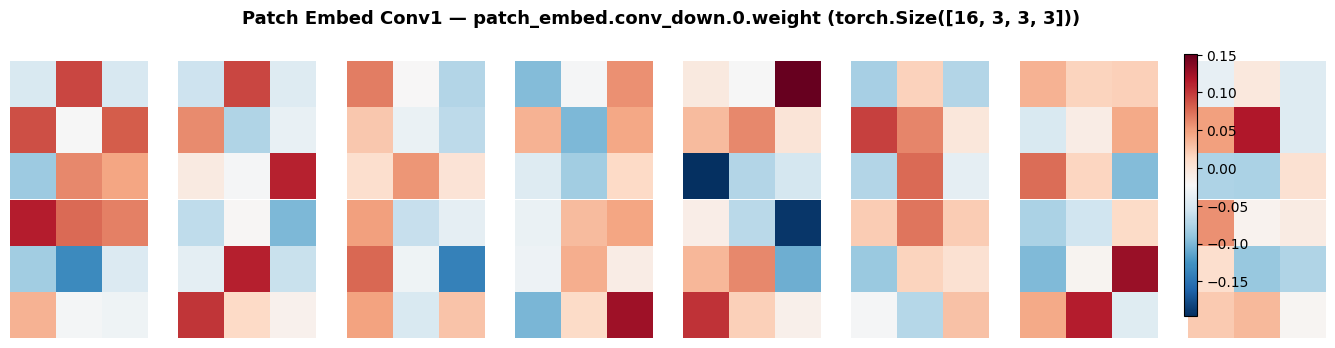

  Saved: ./output_phase3/vnmangoleaf_phase3-20260705-210739/weight_patch_embed_conv2.png


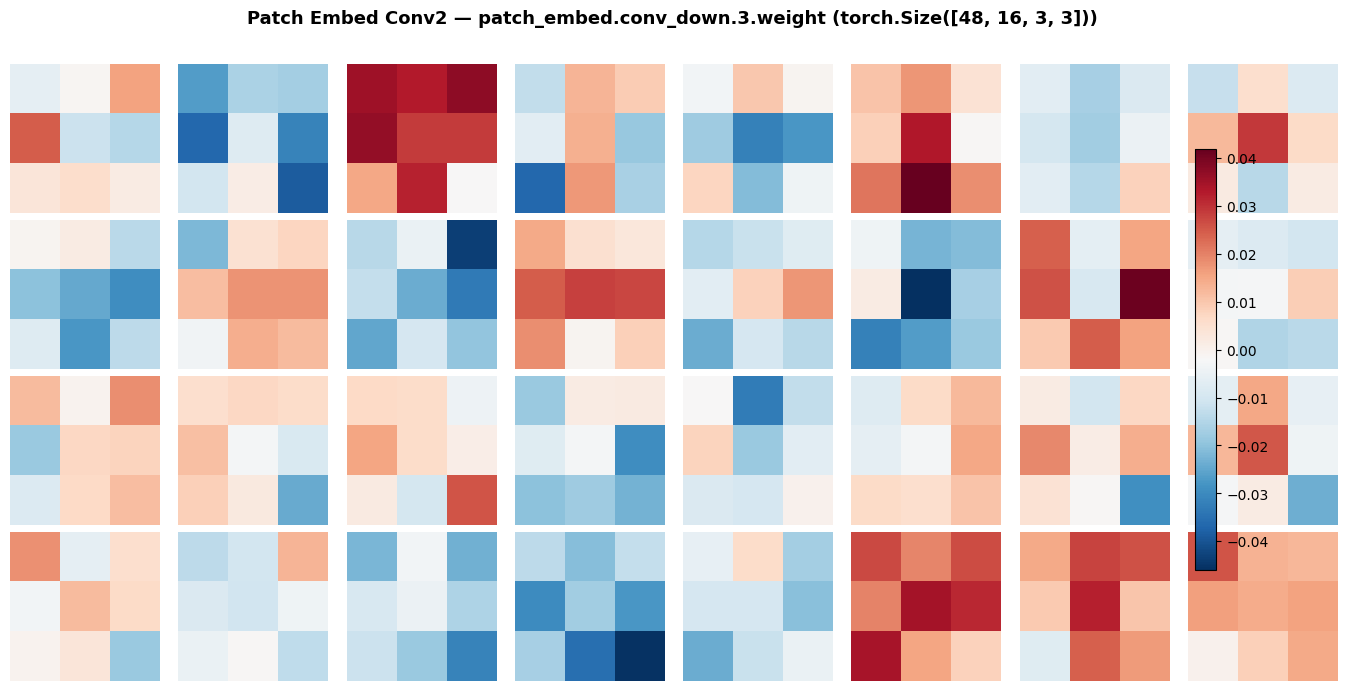

  Saved: ./output_phase3/vnmangoleaf_phase3-20260705-210739/weight_stage1_downsample.png


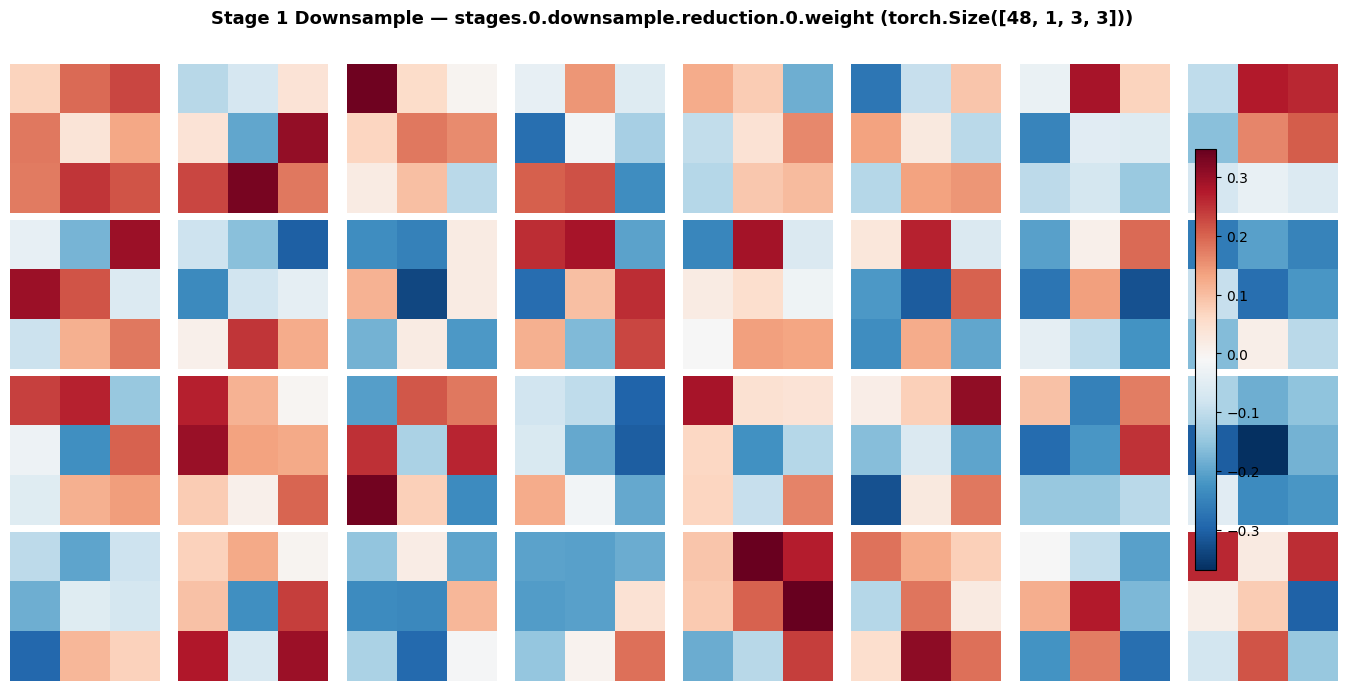

  Saved: ./output_phase3/vnmangoleaf_phase3-20260705-210739/weight_classifier_head.png


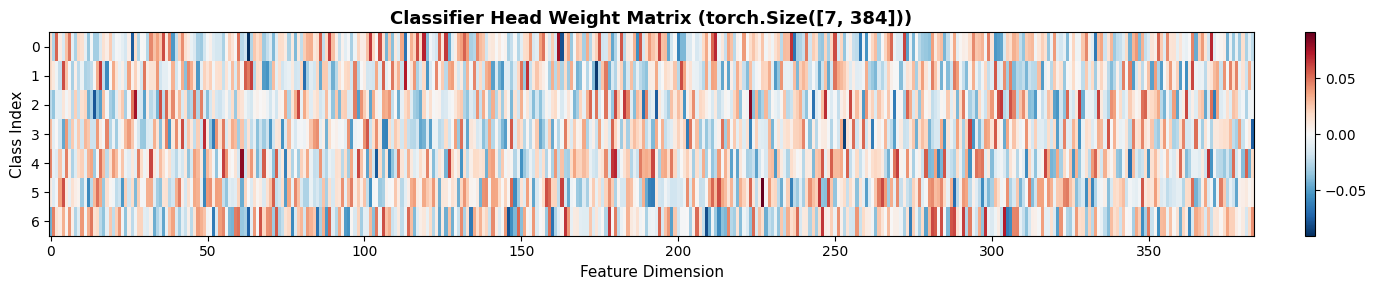

[OK] Conv filter visualizations complete.


In [14]:
# 7a: Convolutional Filter Heatmaps
import os, glob
import numpy as np
import matplotlib.pyplot as plt
import torch

ensure_project_root()


def load_model_for_viz(ckpt_glob, num_classes):
    from models.mango_mamba import mango_mamba_tiny
    matches = sorted(glob.glob(ckpt_glob))
    if not matches:
        return None
    ckpt = torch.load(matches[-1], map_location='cpu', weights_only=False)
    sd = ckpt.get('model_state_dict', ckpt.get('state_dict', ckpt))
    model = mango_mamba_tiny(num_classes=num_classes)
    model.load_state_dict(sd, strict=False)
    model.eval()
    print(f'Loaded: {os.path.basename(matches[-1])}')
    return model


def plot_conv_filters(weight_tensor, title, max_filters=32, save_path=None):
    w = weight_tensor.detach().cpu().numpy()
    if w.ndim == 4:
        w = w.mean(axis=1)          # avg over input channels -> (out, H, W)
    elif w.ndim == 2:
        n_out, n_in = w.shape
        side = int(np.ceil(np.sqrt(n_in)))
        w = np.pad(w, ((0,0),(0,side*side-n_in))).reshape(n_out, side, side)
    n = min(max_filters, w.shape[0])
    cols = min(8, n)
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols*1.7, rows*1.7))
    axes = np.array(axes).reshape(-1)
    vmin, vmax = w[:n].min(), w[:n].max()
    for i in range(n):
        axes[i].imshow(w[i], cmap='RdBu_r', vmin=vmin, vmax=vmax, interpolation='nearest')
        axes[i].axis('off')
    for j in range(n, len(axes)):
        axes[j].axis('off')
    plt.colorbar(axes[0].images[0], ax=axes[:n].tolist(), fraction=0.02, pad=0.04)
    fig.suptitle(title, fontsize=13, fontweight='bold', y=1.01)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=120, bbox_inches='tight')
        print(f'  Saved: {save_path}')
    plt.show()


viz_model = load_model_for_viz('./output_phase3/vnmangoleaf_phase3-*/model_best_inference.pth', 7)
if viz_model is None:
    viz_model = load_model_for_viz('./output_phase1/mangoleafbd_phase1-*/model_best_inference.pth', 8)

run_dir_viz = find_latest_run('./output_phase3/vnmangoleaf_phase3-*') or \
              find_latest_run('./output_phase1/mangoleafbd_phase1-*')

if viz_model is not None:
    sd = viz_model.state_dict()

    # Patch embed conv 1
    for key in ['patch_embed.conv_down.0.weight', 'patch_embed.proj.weight']:
        if key in sd:
            sp = os.path.join(run_dir_viz, 'weight_patch_embed_conv1.png') if run_dir_viz else None
            plot_conv_filters(sd[key], f'Patch Embed Conv1 — {key} ({sd[key].shape})', save_path=sp)
            break

    # Patch embed conv 2
    for key in ['patch_embed.conv_down.3.weight', 'patch_embed.proj2.weight']:
        if key in sd:
            sp = os.path.join(run_dir_viz, 'weight_patch_embed_conv2.png') if run_dir_viz else None
            plot_conv_filters(sd[key], f'Patch Embed Conv2 — {key} ({sd[key].shape})', save_path=sp)
            break

    # Stage 1 downsample depthwise conv
    for key in ['stages.0.downsample.reduction.0.weight', 'stages.0.downsample.conv.weight']:
        if key in sd:
            sp = os.path.join(run_dir_viz, 'weight_stage1_downsample.png') if run_dir_viz else None
            plot_conv_filters(sd[key], f'Stage 1 Downsample — {key} ({sd[key].shape})', save_path=sp)
            break

    # Classifier head
    if 'head.weight' in sd:
        kh = sd['head.weight']  # (num_classes, features)
        sp = os.path.join(run_dir_viz, 'weight_classifier_head.png') if run_dir_viz else None
        fig, ax = plt.subplots(figsize=(14, 3))
        im = ax.imshow(kh.numpy(), cmap='RdBu_r', aspect='auto', interpolation='nearest')
        ax.set_xlabel('Feature Dimension', fontsize=11)
        ax.set_ylabel('Class Index', fontsize=11)
        ax.set_title(f'Classifier Head Weight Matrix ({kh.shape})', fontsize=13, fontweight='bold')
        plt.colorbar(im, fraction=0.015, pad=0.04)
        plt.tight_layout()
        if sp:
            plt.savefig(sp, dpi=120, bbox_inches='tight')
            print(f'  Saved: {sp}')
        plt.show()

    print('[OK] Conv filter visualizations complete.')

In [15]:
# 7b: Feature Embedding t-SNE
import os, glob
import numpy as np
import matplotlib.pyplot as plt
import torch
from timm.data import create_dataset, create_loader, resolve_data_config

ensure_project_root()

try:
    from sklearn.manifold import TSNE
except ImportError:
    import subprocess as _sp
    _sp.run(['pip', 'install', '-q', 'scikit-learn'], check=True)
    from sklearn.manifold import TSNE


def collect_features(model, data_dir, split='val', max_samples=800, batch_size=64):
    model.cuda().eval()
    data_config = resolve_data_config({}, model=model, verbose=False)
    dataset = create_dataset('', root=data_dir, split=split, is_training=False, batch_size=batch_size)
    loader = create_loader(
        dataset, input_size=data_config['input_size'],
        batch_size=batch_size, is_training=False, use_prefetcher=False,
        interpolation=data_config['interpolation'], mean=data_config['mean'],
        std=data_config['std'], num_workers=0, crop_pct=data_config['crop_pct']
    )
    all_feats, all_labels = [], []
    total = 0
    with torch.no_grad(), torch.amp.autocast('cuda'):
        for imgs, labels in loader:
            out = model(imgs.cuda())
            feats = out['features'] if isinstance(out, dict) and 'features' in out else out['logits']
            all_feats.append(feats.cpu().float().numpy())
            all_labels.append(labels.numpy())
            total += imgs.shape[0]
            if total >= max_samples:
                break
    return np.concatenate(all_feats)[:max_samples], np.concatenate(all_labels)[:max_samples]


# Use Phase 3 model on VN-MangoLeaf val, fallback to Phase 1
p3_ckpts = sorted(glob.glob('./output_phase3/vnmangoleaf_phase3-*/model_best_inference.pth'))
use_phase3 = bool(p3_ckpts) and os.path.isdir('./vn_mangoleaf/val')

if use_phase3:
    viz_ckpt     = p3_ckpts[-1]
    viz_data_dir = './vn_mangoleaf'
    viz_ncls     = 7
    viz_classes  = ['Anthracnose','Dieback','Gall Midge','Healthy','Powdery Mildew','Red Rust','Sooty Mold']
    tsne_title   = 'Phase 3 Feature Space — VN-MangoLeaf val (t-SNE)'
else:
    p1_ckpts = sorted(glob.glob('./output_phase1/mangoleafbd_phase1-*/model_best_inference.pth'))
    viz_ckpt     = p1_ckpts[-1] if p1_ckpts else None
    viz_data_dir = './mangoleafBD'
    viz_ncls     = 8
    viz_classes  = ['Anthracnose','Bacterial Canker','Cutting Weevil','Die Back',
                    'Gall Midge','Healthy','Powdery Mildew','Sooty Mould']
    tsne_title   = 'Phase 1 Feature Space — MangoLeafBD val (t-SNE)'

if viz_ckpt is None:
    print('[ERROR] No checkpoint found for feature extraction.')
else:
    from models.mango_mamba import mango_mamba_tiny
    tsne_model = mango_mamba_tiny(num_classes=viz_ncls)
    ckpt_data = torch.load(viz_ckpt, map_location='cpu', weights_only=False)
    tsne_model.load_state_dict(ckpt_data.get('model_state_dict', ckpt_data.get('state_dict', ckpt_data)), strict=False)

    print(f'Extracting features from {viz_data_dir}/val ...')
    feats, labels = collect_features(tsne_model, viz_data_dir, split='val', max_samples=800)
    del tsne_model; torch.cuda.empty_cache()
    print(f'  {feats.shape[0]} vectors, dim {feats.shape[1]}')

    print('Running t-SNE...')
    emb = TSNE(n_components=2, perplexity=30, n_iter=1000, random_state=42).fit_transform(feats)

    cmap = plt.get_cmap('tab10')
    fig, ax = plt.subplots(figsize=(11, 9))
    for ci, cname in enumerate(viz_classes):
        mask = labels == ci
        ax.scatter(emb[mask,0], emb[mask,1], color=cmap(ci/len(viz_classes)),
                   label=cname, alpha=0.75, s=20, edgecolors='none')
    ax.set(xlabel='t-SNE Dim 1', ylabel='t-SNE Dim 2', title=tsne_title)
    ax.title.set_fontsize(14); ax.title.set_fontweight('bold')
    ax.legend(fontsize=10, framealpha=0.85); ax.grid(alpha=0.2)
    plt.tight_layout()

    run_dir_t = find_latest_run('./output_phase3/vnmangoleaf_phase3-*') or \
                find_latest_run('./output_phase1/mangoleafbd_phase1-*')
    if run_dir_t:
        sp = os.path.join(run_dir_t, 'weight_tsne_features.png')
        plt.savefig(sp, dpi=150, bbox_inches='tight')
        print(f'Saved t-SNE: {sp}')
    plt.show()

Extracting features from ./vn_mangoleaf/val ...


ValueError: persistent_workers option needs num_workers > 0

---
## Section 8: Cross-Phase Comparison Summary

In [ ]:
import os, glob, json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML

ensure_project_root()

phase_configs = [
    ('Phase 1 — MangoLeafBD (8 cls)',  './output_phase1/mangoleafbd_phase1-*/training_results.json'),
    ('Phase 2 — Combined (8 cls)',      './output_phase2/combined_phase2-*/training_results.json'),
    ('Phase 3 — VN-MangoLeaf (7 cls)', './output_phase3/vnmangoleaf_phase3-*/training_results.json'),
]

rows_html = ''
plot_data = []
bg = ['#ecf0f1', 'white', '#ecf0f1']

for idx, (label, pattern) in enumerate(phase_configs):
    matches = sorted(glob.glob(pattern))
    if not matches:
        rows_html += f"<tr><td colspan='8' style='padding:6px 12px;color:#e74c3c;'>&#9888; {label}: results not found</td></tr>"
        continue
    with open(matches[-1]) as f:
        r = json.load(f)
    vm = r.get('validation_metrics', {})
    tm = r.get('test_metrics', {})
    es = r.get('early_stopping', {})
    rows_html += f"""
    <tr style='background:{bg[idx]};'>
      <td style='padding:7px 12px;font-weight:bold;'>{label}</td>
      <td style='padding:7px 12px;text-align:center;'>{vm.get('accuracy',0)*100:.2f}%</td>
      <td style='padding:7px 12px;text-align:center;'>{tm.get('accuracy',0)*100:.2f}%</td>
      <td style='padding:7px 12px;text-align:center;'>{vm.get('f1_score',0)*100:.2f}%</td>
      <td style='padding:7px 12px;text-align:center;'>{tm.get('f1_score',0)*100:.2f}%</td>
      <td style='padding:7px 12px;text-align:center;'>{vm.get('precision',0)*100:.2f}%</td>
      <td style='padding:7px 12px;text-align:center;'>{vm.get('recall',0)*100:.2f}%</td>
      <td style='padding:7px 12px;text-align:center;'>{r.get('training_time_formatted','?')} ({es.get('epochs_completed',r.get('epochs_completed','?'))} ep)</td>
    </tr>"""
    plot_data.append({'label': label, 'val_acc': vm.get('accuracy',0)*100,
                      'test_acc': tm.get('accuracy',0)*100,
                      'val_f1':   vm.get('f1_score',0)*100,
                      'test_f1':  tm.get('f1_score',0)*100})

display(HTML(f"""
<h2 style='font-family:sans-serif;color:#1a252f;border-bottom:2px solid #27ae60;padding-bottom:4px;'>Cross-Phase Results Summary</h2>
<table style='border-collapse:collapse;font-family:sans-serif;font-size:13px;width:100%;'>
  <thead><tr style='background:#1a252f;color:white;'>
    <th style='padding:8px 12px;text-align:left;'>Phase</th>
    <th style='padding:8px 12px;'>Val Acc</th><th style='padding:8px 12px;'>Test Acc</th>
    <th style='padding:8px 12px;'>Val F1</th><th style='padding:8px 12px;'>Test F1</th>
    <th style='padding:8px 12px;'>Val Precision</th><th style='padding:8px 12px;'>Val Recall</th>
    <th style='padding:8px 12px;'>Training Time</th>
  </tr></thead><tbody>{rows_html}</tbody>
</table>
"""))

if plot_data:
    labels_s = [d['label'].split('--')[0].strip().split(' (')[0] for d in plot_data]
    x = np.arange(len(plot_data)); w = 0.2
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.bar(x-1.5*w, [d['val_acc']  for d in plot_data], w, label='Val Accuracy',  color='#3498db', alpha=0.85)
    ax.bar(x-0.5*w, [d['test_acc'] for d in plot_data], w, label='Test Accuracy', color='#2980b9', alpha=0.85)
    ax.bar(x+0.5*w, [d['val_f1']   for d in plot_data], w, label='Val F1',        color='#2ecc71', alpha=0.85)
    ax.bar(x+1.5*w, [d['test_f1']  for d in plot_data], w, label='Test F1',       color='#27ae60', alpha=0.85)
    ax.set_xticks(x); ax.set_xticklabels(labels_s, fontsize=11)
    ax.set(ylabel='Score (%)')
    ax.set_title('MangoMamba — Cross-Phase Performance Comparison', fontsize=14, fontweight='bold')
    ax.set_ylim(75, 102); ax.legend(fontsize=11); ax.grid(axis='y', alpha=0.3)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0f}%'))
    plt.tight_layout()
    for pat in ['./output_phase3/vnmangoleaf_phase3-*',
                './output_phase2/combined_phase2-*',
                './output_phase1/mangoleafbd_phase1-*']:
        sd = find_latest_run(pat)
        if sd:
            sp = os.path.join(sd, 'cross_phase_summary.png')
            plt.savefig(sp, dpi=150, bbox_inches='tight')
            print(f'Summary chart saved: {sp}')
            break
    plt.show()